# Exact, Jastrow and RBM overlap distributions

**System sizes:** periodic kagome, three spins per unit cell,
$N=3L^2$. The original exact/variational sections use **$L=2$, $2\times2$
unit cells, $N=12$ spins**. The measured larger-system sections use
**$L=4$, $4\times4$ unit cells, $N=48$ spins**. All results use **$h=0.15$**.

**Where are the $L=4$ results?** Scroll to **L=4, N=48: before and after
projection**, followed by **L=4, N=48: higher-field distributions**.
The $L=2$ exact-guide, exact-ground-state, guide-MCMC and GFMC comparison
appears immediately before them. Plot-panel counts are not lattice sizes.

This follows `exact_guide_overlap_distributions.ipynb`: two independent spin
configurations of the **same disorder** give $q=N^{-1}\sum_i s_i t_i$.
For $L=2$, $N=12$, there are 13 allowed values from -1 to 1, spaced by 1/6.
The plotted ordinate is **probability mass per bin**, whose heights sum to one.
Connecting lines are visual aids, not a continuous density.

$$P_J(q)=\sum_{s,t}p_J(s)p_J(t)\,\mathbf1[N^{-1}s\cdot t=q].$$

Exact uses $p=\psi_0^2$; each unprojected guide uses normalized $p=\psi_T^2$.
The XOR/Walsh convolution matches the original notebook. Normalization and
first/second moments are independently checked from magnetizations and pairs.
The original exact/variational plots in this first part are **unprojected**. Saved GFMC moment spectra cannot reconstruct
the full $P(q)$; a separate histogram estimator would be required.

The first comparison shows the four existing diagnostic contexts at $h=0.15$.
Guides were fitted using full-basis variational energy, without ground-state
labels. Minimum-energy seed selection precedes evaluation. This is an L2
ansatz/optimization test, not scalable sampled-training validation.


## Priority: iterative feedback at $L=6,8,10$

**User-directed compute priority, 2026-11-03.** New research compute now targets
$L=6,8,10$ ($N=108,192,300$), not an extended small-system campaign.
The five-arm $L=2$ continuation proposal was never launched. Nineteen short
implementation tests passed on AutoDL, including CPU/CUDA rates at the requested
sizes, exact tiny-state kernels, restart/dispatch equality and independent
raw-data reconstruction. These are implementation checks, not physical convergence.

Three detached size workers launched at **2026-11-03T15:12:24.982677Z**.
Each size covers disorders60000/60001, seeds0/1, $h=.15$, $\Gamma=.60$,
and two paired arms from the same starting checkpoint:

- **Baseline:**1024 walkers; persistent two-copy Gibbs negatives.
- **Robust:**four independent1024-walker populations;16-temperature two-copy
  replica exchange; bounded empirical log-density steps.

Every context receives12 feedback stints. Each stint uses equil8/collect12,
delta.1,64 target samples/block,1000 likelihood updates,lr.001,batch256 and
10 negative sweeps/update. Two-stint round-robin dispatch exposes contexts
early. L6 starts from archived VMC400 controls; L8/L10 create repaired VMC
warm starts at Gamma1.5,.75,.60 (400 updates/stage). Existing L4 production
and the finite original L6 pilot continue.

Frozen guides at six and twelve stints and each starting guide receive new
four-population GFMC measurements:512 walkers/population,equil16,forward16,
eight cycles,two repeats. Same measurement task/RNG identities within each
context; separate model/source/device provenance. All sampling and ancestry
alarms are retained. Training is prioritized before these frozen measurements.

Finite scope:24 training contexts,288 stints,112 new GFMC runs plus eight reused
L6 fixed-guide controls. One worker/size, no deadline or monitoring loop.
The robust arm costs more compute and combines interventions; this is not
a compute-matched attribution of each ingredient. Physical results are pending.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown,display
scaling_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
scaling_archive=scaling_root/'data/kagome/ltfim_disorder_scaling_v1/repaired_campaign/20261103_v2/feedback_scaling/20261103T151551Z'
scaling_hashes=json.loads((scaling_archive/'sha256.json').read_text())
for relative,digest in scaling_hashes.items():
    assert hashlib.sha256((scaling_archive/relative).read_bytes()).hexdigest()==digest,relative
scaling_snapshot=json.loads((scaling_archive/'snapshot.json').read_text())
scaling_tests=json.loads((scaling_archive/'validation/scaling_regressions.json').read_text())
assert scaling_tests['passed'] and scaling_tests['tests_run']==19 and scaling_tests['skipped']==0
display(Markdown('**Saved status: '+scaling_snapshot['utc']+'** — dated checkpoint, not a live monitor.'))
table=['| Size | Alive | Phase | Current context | Completed stints | Failures |',
       '|---|---|---|---|---:|---:|']
for r in scaling_snapshot['scaling']:
    s=r['status'];c=s.get('current') or {}
    detail=' / '.join(str(c.get(k,'')) for k in ['arm','sample_id','seed'])
    done=sum(x.get('completed_stints',0) for x in r['training_status'])
    table.append(f"| L{r['L']} | {r['alive']} | {s.get('state','pending')} | {detail} | {done}/96 | {len(s.get('failures',[]))} |")
display(Markdown(chr(10).join(table)))
print('Verified archive files:',len(scaling_hashes))
print('Implementation tests:',scaling_tests['tests_run'],'passed; none skipped')


**Saved status: 2026-11-03T15:15:51.232990+00:00** — dated checkpoint, not a live monitor.

| Size | Alive | Phase | Current context | Completed stints | Failures |
|---|---|---|---|---:|---:|
| L6 | True | adapting | robust / 60000 / 0 | 0/96 | 0 |
| L8 | True | initial_vmc |  / 60000 / 0 | 0/96 | 0 |
| L10 | True | initial_vmc |  / 60000 / 0 | 0/96 | 0 |

Verified archive files: 306
Implementation tests: 19 passed; none skipped


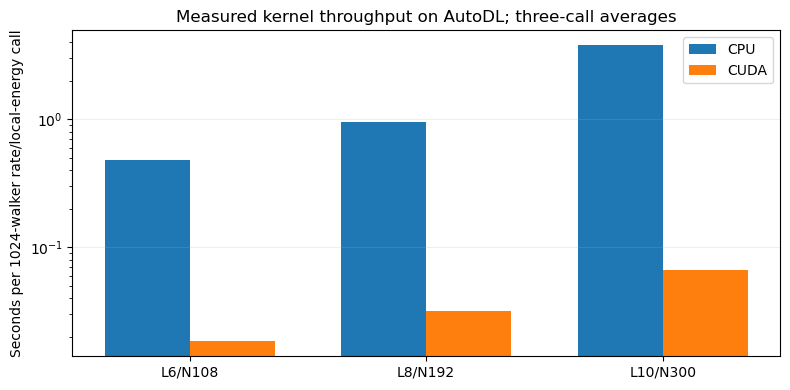

Kernel speedups: {6: 26.11173279393316, 8: 29.354975399853156, 10: 56.660341240816024}


In [2]:
scaling_benchmark=json.loads((scaling_archive/'validation/kernel_benchmark.json').read_text())
fig,ax=plt.subplots(figsize=(8,4))
positions=np.arange(3)
for device,offset in [('cpu',-.18),('cuda',.18)]:
    values=[next(r['seconds_per_1024_rates'] for r in scaling_benchmark if r['L']==L and r['device']==device) for L in [6,8,10]]
    ax.bar(positions+offset,values,width=.36,label=device.upper())
ax.set(xticks=positions,xticklabels=['L6/N108','L8/N192','L10/N300'],yscale='log',
       ylabel='Seconds per 1024-walker rate/local-energy call',
       title='Measured kernel throughput on AutoDL; three-call averages')
ax.legend();ax.grid(axis='y',alpha=.2);fig.tight_layout();plt.show()
print('Kernel speedups:',{L:next(r['seconds_per_1024_rates'] for r in scaling_benchmark if r['L']==L and r['device']=='cpu')/next(r['seconds_per_1024_rates'] for r in scaling_benchmark if r['L']==L and r['device']=='cuda') for L in [6,8,10]})


**Algorithm details.** The tempered marginal is
$q_eta(s)\propto\exp(2eta a\cdot s)\prod_j[2\cosh(eta(sW+b)_j)]^2$.
It is uniform at beta0 and exactly $\psi^2$ at beta1; at intermediate beta
it is not $\psi^{2eta}$. Exchanges use the marginal-density ratio.
Backtracking limits each empirical centered change in $2\log\psi$ to RMS.025
and max.15 on the current positive/negative minibatch; this is not a global KL
or unvisited-state bound. Four population islands retain separate ancestors,
normalizations and RNGs; they pool equal sample counts without ancestry weighting.

CUDA changes only batched guide evaluation, not the continuous-time event or
log-resampling mathematics. CPU/CUDA roundoff can alter realized trajectories.
The measured26–57x speedups are kernel benchmarks, not total-run speedups.

### Original L6 pilot: genealogy motivates the stronger arm

High one-step weight ESS and thousands of distinct configurations did not
prevent severe ancestry concentration. The following raw-data diagnostic is
training evidence only; no guide-update checkpoint is a pure-observable result.

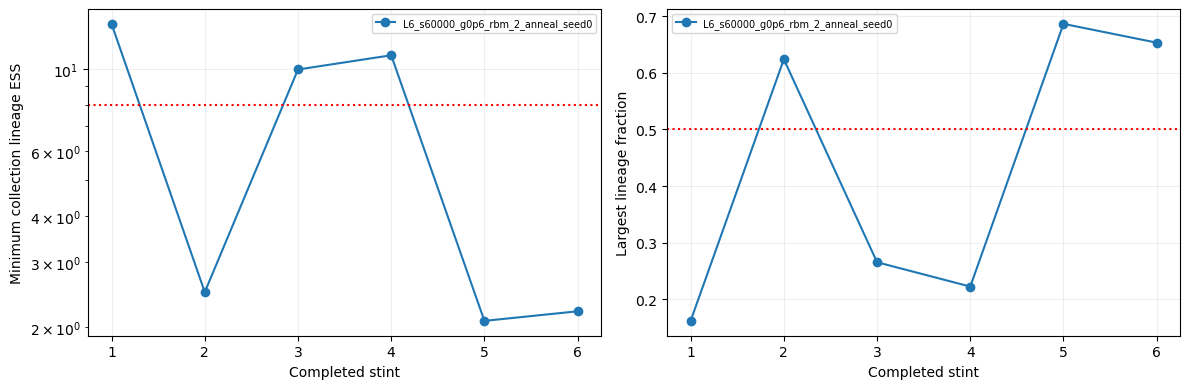

Archived original-pilot stints: 6 training ancestry alarms: 3


In [3]:
pilot_rows=[]
for path in sorted((scaling_archive/'original_l6/training').glob('*/summary.json')):
    for row in json.loads(path.read_text())['rows']:
        folder=path.parent/f"stint_{row['stint']:03d}"
        raw=np.load(folder/'walkers.npz')
        collection=raw['lineages'][80:]
        np.testing.assert_allclose(collection[:,0].min(),row['minimum_training_lineage_ess'])
        np.testing.assert_allclose(collection[:,1].max(),row['largest_training_lineage'])
        pilot_rows.append(dict(context=path.parent.name,**row,weight_ess_min=float(raw['weight_ess'].min())))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in sorted({r['context'] for r in pilot_rows}):
    rows=[r for r in pilot_rows if r['context']==name];x=[r['stint']+1 for r in rows]
    axes[0].plot(x,[r['minimum_training_lineage_ess'] for r in rows],'o-',label=name)
    axes[1].plot(x,[r['largest_training_lineage'] for r in rows],'o-',label=name)
axes[0].set(yscale='log',xlabel='Completed stint',ylabel='Minimum collection lineage ESS')
axes[0].axhline(8,color='red',ls=':')
axes[1].set(xlabel='Completed stint',ylabel='Largest lineage fraction');axes[1].axhline(.5,color='red',ls=':')
for ax in axes:ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();plt.show()
print('Archived original-pilot stints:',len(pilot_rows),'training ancestry alarms:',sum(r['training_ancestry_alarm'] for r in pilot_rows))


### First completed large-size feedback stints

This later checkpoint retains the first robust-arm training results and all
alarms. The first target was collected using the starting guide, before any
new likelihood fit; its genealogy therefore cannot measure the effect of the
subsequent tempered fit. Improvements between two training stints are not
independent physical-observable validation.

In [4]:
scaling_progress=scaling_root/'data/kagome/ltfim_disorder_scaling_v1/repaired_campaign/20261103_v2/feedback_scaling/progress/20261103T152007Z'
progress_hashes=json.loads((scaling_progress/'sha256.json').read_text())
for relative,digest in progress_hashes.items():
    assert hashlib.sha256((scaling_progress/relative).read_bytes()).hexdigest()==digest,relative
progress_snapshot=json.loads((scaling_progress/'snapshot.json').read_text())
display(Markdown('**Later checkpoint: '+progress_snapshot['utc']+'**'))
table=['| Size / arm / context | Stint | Worst island ESS | Largest lineage | Ancestry alarm | Tempering round trips | Min exchange | Bounded / rejected steps |',
       '|---|---:|---:|---:|---|---:|---:|---:|']
for entry in progress_snapshot['rows']:
    for group in entry['training']:
        for r in group['rows']:
            sampler=r.get('negative_sampler') or {}
            exchange=min(sampler.get('exchange_fraction',[float('nan')]))
            table.append(f"| L{entry['L']} / {group['arm']} / {group['context']} | {r['stint']+1} | {r['minimum_training_lineage_ess']:.3f} | {r['largest_training_lineage']:.3f} | {r['training_ancestry_alarm']} | {sampler.get('round_trips','—')} | {exchange:.3f} | {r.get('bounded_steps',0)} / {r.get('rejected_steps',0)} |")
    for r in entry['initial']:
        print('Warm start:',entry['L'],'stage field',r['gamma'],'update',r['step'],'of 400; no feedback/physical result yet')
display(Markdown(chr(10).join(table)))
print('Verified later-checkpoint files:',len(progress_hashes))


**Later checkpoint: 2026-11-03T15:20:07.108855+00:00**

Warm start: 8 stage field 1.5 update 75 of 400; no feedback/physical result yet
Warm start: 10 stage field 1.5 update 50 of 400; no feedback/physical result yet


| Size / arm / context | Stint | Worst island ESS | Largest lineage | Ancestry alarm | Tempering round trips | Min exchange | Bounded / rejected steps |
|---|---:|---:|---:|---|---:|---:|---:|
| L6 / robust / L6_s60000_g0p6_rbm_2_anneal_seed0 | 1 | 1.161 | 0.928 | True | 76699 | 0.358 | 1000 / 0 |
| L6 / robust / L6_s60000_g0p6_rbm_2_anneal_seed0 | 2 | 14.858 | 0.197 | False | 79172 | 0.371 | 1000 / 0 |

Verified later-checkpoint files: 16


**Next scientific output:** independently measured P(q),q2,connected spectra,
energy and ancestry at L6/L8/L10, compared across six/twelve stints and fixed
guides. Population/time/start dependence and uncertainty remain necessary
before calling any result converged. No critical-field or exponent claim is
supported by this launch or the kernel speedups.

The earlier dated notebook sections remain historical checkpoints. The full
new method and finite scope are documented in `code/transformer_qmc/FEEDBACK_SCALING.md`.

## Iterative PQMC–RBM feedback: completed $L=2$ validation

**New evidence, 2026-11-03:** both seeds completed all six feedback stints,
followed by independent final-guide sampling and four-population GFMC.
This diagnostic is periodic kagome **$L=2$, $N=12$, $h=0.15$, $\Gamma=0.60$,
disorder 60000**, not a disorder ensemble. Every seed and stint is retained.

**Method correction.** Earlier VMC-budget extensions fit energy and then
project with a fixed guide; they omit projected-walker feedback. Here each
fixed-guide stint produces mixed walkers $f_s\propto\psi_s\psi_0$; normalized
$\psi_\theta^2$ is fitted by likelihood, and $\psi_\theta$ guides the next stint.
Ideally $\psi_{s+1}\propto\sqrt{\psi_s\psi_0}$. The two-hidden-copy sampler
matches our log-amplitude convention; this differs from the single-RBM density
architecture in the papers. Exact information is used only for evaluation.
See Pilati, Inack & Pieri, *Phys. Rev. E* **100**, 043301 (2019),
arXiv:1907.00907, and Brodoloni & Pilati, arXiv:2407.05978, Sec. II.2.

Each stint uses 1024 walkers, equilibration8/collection12, branching interval0.1,
64 walker configurations/block, 1000 Adam updates at 0.001, 256 persistent
negative chains and ten Gibbs sweeps/update. New populations equilibrate at
every guide change. Forward tags and physical measurement averages never cross
an adaptive update. The frozen final-guide measurements use new populations
and RNGs: 512 walkers per independent population, equilibration16/forward16,
eight cycles, two repeats per seed.

**Scope:** this is an implementation/finite-observable screen. Neither it nor
the historical figures certify ground-state convergence. The finite matched
$L=6$ pilot has launched; its physical results are pending. Earlier dated
campaign snapshots remain below as historical records.

In [5]:
%matplotlib inline
from pathlib import Path
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
feedback_root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
feedback_folder=feedback_root/'data/kagome/ltfim_disorder_scaling_v1/repaired_campaign/20261103_v2/self_learning'
feedback_hashes=json.loads((feedback_folder/'sha256.json').read_text())
for relative,digest in feedback_hashes.items():
    assert hashlib.sha256((feedback_folder/relative).read_bytes()).hexdigest()==digest,relative
feedback_load=lambda name:json.loads((feedback_folder/name).read_text())
feedback_training=feedback_load('validation/training_report.json')['rows']
feedback_measured=feedback_load('validation/summary.json')
feedback_guides=feedback_load('validation/guides.json')['rows']
feedback_runs=feedback_load('validation/measurements.json')['rows']
assert len(feedback_training)==12 and len(feedback_runs)==4
for r in feedback_runs:
    grid=np.asarray(r['q_grid']);mass=np.asarray(r['mass'])
    np.testing.assert_allclose([mass.sum(),grid@mass,grid**2@mass],[1,r['q'],r['q2']],atol=1e-12)
    assert not r['ancestry_alarm']
print('Verified feedback archive files:',len(feedback_hashes))
print('Completed stints:',len(feedback_training),'independent final-guide GFMC runs:',len(feedback_runs))
print('Exact eigensolver residual:',feedback_measured['exact']['residual'])


Verified feedback archive files: 586
Completed stints: 12 independent final-guide GFMC runs: 4
Exact eigensolver residual: 1.230036655081046e-14


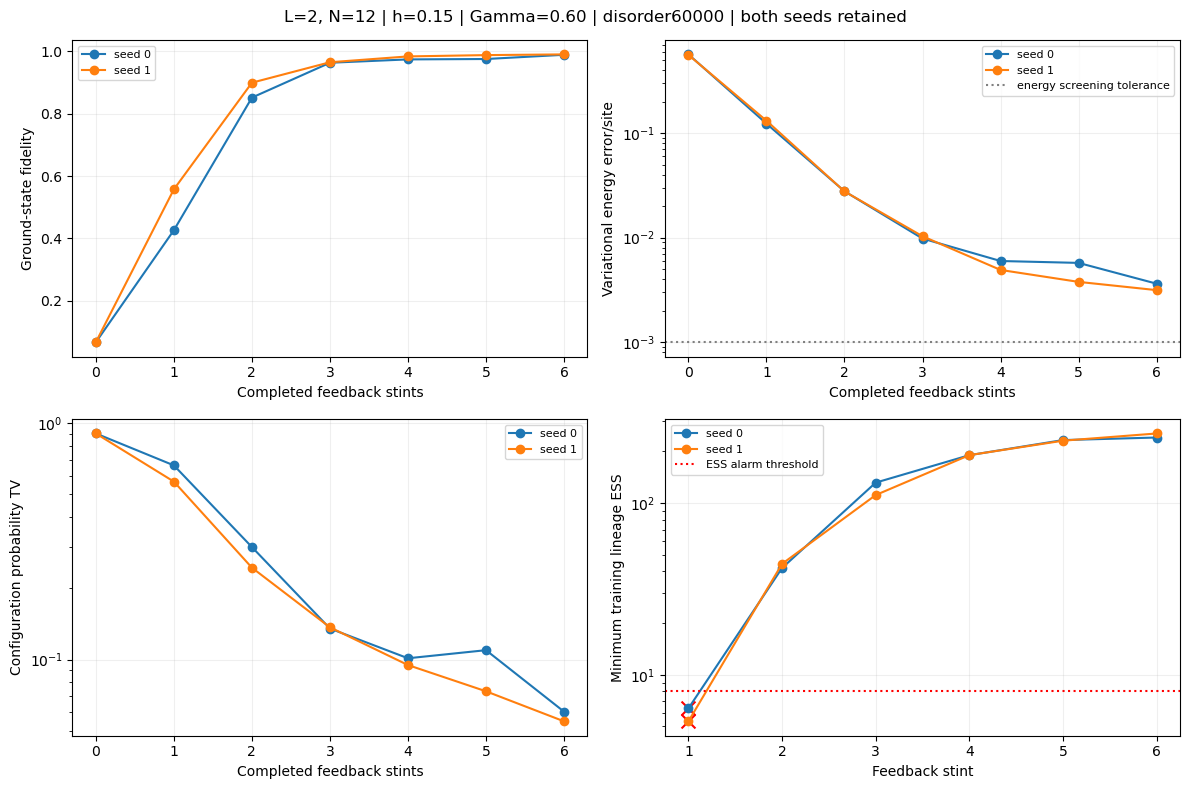

In [6]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for seed,color in [(0,'tab:blue'),(1,'tab:orange')]:
    group=sorted([r for r in feedback_training if r['seed']==seed],key=lambda r:r['stint'])
    evaluations=[group[0]['before']]+[r['after'] for r in group]
    for ax,key,label in [(axes[0,0],'fidelity','Ground-state fidelity'),
                         (axes[0,1],'energy_error_per_site','Variational energy error/site'),
                         (axes[1,0],'ground_probability_tv','Configuration probability TV')]:
        ax.plot(range(7),[r[key] for r in evaluations],'o-',color=color,label=f'seed {seed}')
        ax.set(xlabel='Completed feedback stints',ylabel=label)
    axes[1,1].plot(range(1,7),[r['minimum_training_lineage_ess'] for r in group],
                   'o-',color=color,label=f'seed {seed}')
    alarmed=[r for r in group if r['training_ancestry_alarm']]
    axes[1,1].scatter([r['stint']+1 for r in alarmed],[r['minimum_training_lineage_ess'] for r in alarmed],
                      marker='x',s=100,color='red')
axes[0,1].set_yscale('log');axes[1,0].set_yscale('log');axes[1,1].set_yscale('log')
axes[0,1].axhline(.001,color='gray',ls=':',label='energy screening tolerance')
axes[1,1].axhline(8,color='red',ls=':',label='ESS alarm threshold')
axes[1,1].set(xlabel='Feedback stint',ylabel='Minimum training lineage ESS')
for ax in axes.flat:ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('L=2, N=12 | h=0.15 | Gamma=0.60 | disorder60000 | both seeds retained')
fig.tight_layout();plt.show()


| Seed | Final fidelity | Guide energy error/site | Configuration TV | Final training ESS | GFMC P(q) TV | GFMC q2 error | GFMC max spectrum error | GFMC minimum ESS |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0.989079 | 0.003632 | 0.060198 | 240.61 | 0.006969 | -0.001035 | 1.76% | 85.67 |
| 1 | 0.990386 | 0.003151 | 0.054781 | 254.02 | 0.009082 | -0.004879 | 1.43% | 76.70 |

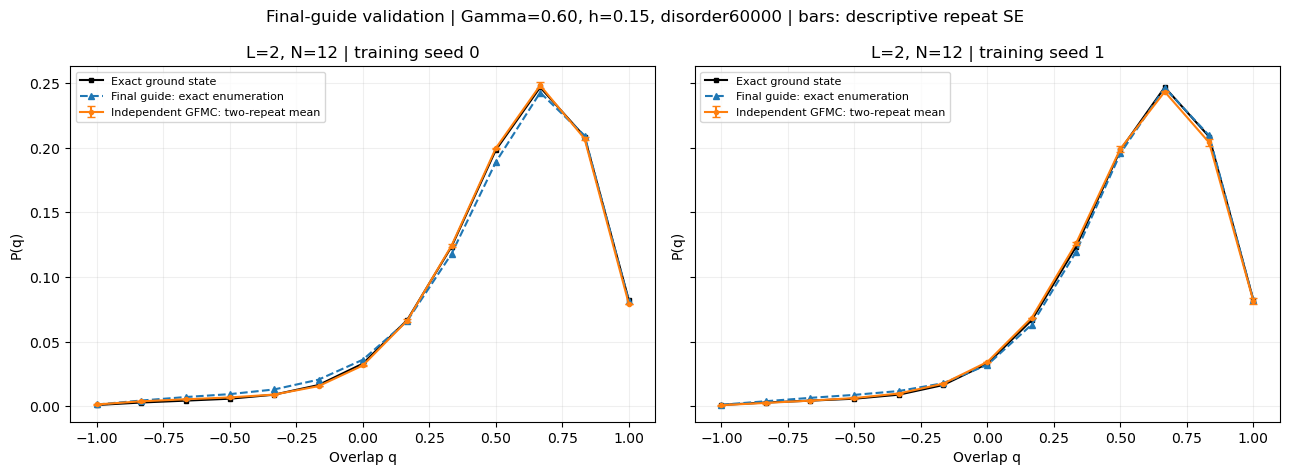

In [7]:
feedback_table=['| Seed | Final fidelity | Guide energy error/site | Configuration TV | Final training ESS | GFMC P(q) TV | GFMC q2 error | GFMC max spectrum error | GFMC minimum ESS |',
                '|---|---:|---:|---:|---:|---:|---:|---:|---:|']
for seed in [0,1]:
    t=next(r for r in feedback_training if r['seed']==seed and r['stint']==5)
    r=next(r for r in feedback_measured['rows'] if r['seed']==seed)
    relative=np.max(np.abs(np.asarray(r['mean']['spectrum'])-feedback_measured['exact']['spectrum'])/np.asarray(feedback_measured['exact']['spectrum']))
    feedback_table.append(f"| {seed} | {t['after']['fidelity']:.6f} | {t['after']['energy_error_per_site']:.6f} | {t['after']['ground_probability_tv']:.6f} | {t['minimum_training_lineage_ess']:.2f} | {r['errors']['histogram_tv']:.6f} | {r['errors']['q2_error']:.6f} | {relative:.2%} | {r['minimum_descendant_ess']:.2f} |")
display(Markdown(chr(10).join(feedback_table)))
fig,axes=plt.subplots(1,2,figsize=(13,4.8),sharex=True,sharey=True)
feedback_q=np.asarray(feedback_measured['exact']['q_grid'])
for seed,ax in enumerate(axes):
    g=next(r for r in feedback_guides if r['seed']==seed)
    r=next(r for r in feedback_measured['rows'] if r['seed']==seed)
    ax.plot(feedback_q,feedback_measured['exact']['mass'],'ks-',ms=3,label='Exact ground state')
    ax.plot(feedback_q,g['mass'],'^--',ms=4,label='Final guide: exact enumeration')
    ax.errorbar(feedback_q,r['mean']['mass'],yerr=r['descriptive_repeat_se']['mass'],
                fmt='o-',ms=3,capsize=3,label='Independent GFMC: two-repeat mean')
    ax.set(title=f'L=2, N=12 | training seed {seed}',xlabel='Overlap q',ylabel='P(q)')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('Final-guide validation | Gamma=0.60, h=0.15, disorder60000 | bars: descriptive repeat SE')
fig.tight_layout();plt.show()


**Interpretation and uncertainty.** The final variational guide energy errors
remain 0.00363/0.00315 per site. After independent GFMC, overlap TV is
0.00697/0.00908 and maximum connected-spectrum relative error is 1.76%/1.43%;
all four measurements avoid ancestry alarms. Configuration-probability TV
and overlap TV are different statistics. Two-repeat SEs are descriptive, not
confidence bounds on population, projection-time or starting-state bias.

Frozen random/up/down Gibbs tests use 256 new chains/start, 500 burn sweeps,
then 100 samples separated by ten sweeps. Negative-phase sufficient-statistic
RMS errors against exact model expectations are 0.0039–0.0059; the largest
component discrepancy is 3.08 chain-wise SE. These checks do not prove that
adaptive negative chains were equilibrated throughout training or at L6.

Five mathematical/sampler/restart regressions passed, including exact
interrupted-fit continuation on CPU and CUDA separately. All 12 before/after
exact evaluations were independently recomputed on CPU; checkpoint continuity,
raw arrays and 56 training hashes were checked. The complete archive includes
all stints, models, optimizer/RNG checkpoints and the first-stint ancestry alarms.

### Finite L6 feedback pilot and existing campaigns

The L2 screen supports a **diagnostic** L6 comparison. The pilot launched at
2026-11-03T14:40:16Z with one sequential worker and no wall-clock deadline:
Gamma=.60, disorders60000/60001, seeds0/1, matching the 400-target-update VMC
checkpoint in each control. Each context receives six feedback stints under
the same pilot training settings, frozen random/up/down sampling checks, then
two matched final-guide measurements. Total: four contexts, 24 stints and
eight GFMC measurements. Model hashes differ; measurement settings and RNG
identities match the controls. No seed or alarmed measurement is selected away.
L6 ground-state convergence remains unresolved; its pilot outputs are pending.
The following saved status is a checkpoint, not a live monitor.

In [8]:
feedback_snapshot=feedback_load('campaign_snapshot.json')
display(Markdown('**Saved campaign status: '+feedback_snapshot['utc']+'**'))
feedback_status=['| Campaign | Alive at snapshot | Fits/milestones | Completed runs | Ancestry alarms | Failures |',
                 '|---|---|---:|---:|---:|---:|']
for row in feedback_snapshot['rows']:
    status=row['status']; fits=status.get('completed_milestones',status.get('completed_extensions',status.get('completed_fits','—')))
    feedback_status.append(f"| {row['campaign']} | {row['alive']} | {fits} | {row['saved_runs']} | {row['ancestry_alarms']} | {len(row['failures'])} |")
display(Markdown(chr(10).join(feedback_status)))
print('L6 feedback launch:',feedback_load('l6_launch/launch.json'))


**Saved campaign status: 2026-11-03T14:38:08.280813+00:00**

| Campaign | Alive at snapshot | Fits/milestones | Completed runs | Ancestry alarms | Failures |
|---|---|---:|---:|---:|---:|
| l6-convergence-20261103-v1 | True | 25 | 37 | 37 | 0 |
| extended-rbm-20261103-v1 | True | 4 | 10 | 10 | 0 |
| ancestry-diagnostic-20261103-v1 | True | — | 9 | 8 | 0 |
| l6-reference-fields-20261103-v1 | True | 2 | 0 | 0 | 0 |
| l4-production-20261103-v1 | True | 39 | 80 | 23 | 0 |

L6 feedback launch: {'pid': 391669, 'command': ['/root/miniconda3/bin/python', '-u', '-m', 'transformer_qmc.self_learning_l6_pilot', '--anchor', '/root/autodl-tmp/l6-convergence-20261103-v1/results', '--validation', '/root/autodl-tmp/self-learning-rbm-20261103-v1/validation', '--output', '/root/autodl-tmp/self-learning-l6-20261103-v1/results'], 'utc': '2026-11-03T14:40:16.077328+00:00', 'contexts': 4, 'planned_stints': 24, 'planned_projections': 8, 'workers': 1, 'deadline': None, 'ground_state_qualified': False}


## Corrected campaign: compute allocation and progress

**Production dispatch paused at 2026-11-03T10:01:10.713605+00:00 for convergence diagnosis.** The combined production processes stopped; saved checkpoints are preserved. L6 convergence has priority; see the current plan for the separate L4 continuation.

**Snapshot: 2026-11-03T10:10:05.318406+00:00 (UTC).** This is a saved status, not a live monitor.

| Work | Status | Completed training fits | Completed GFMC runs | Compute allocation |
|---|---|---:|---:|---|
| disorder-scaling-20261103-v1 | Retired; preserved legacy output | 320 | 480 | Zero workers |
| disorder-scaling-fine-20261103-v1 | Retired; preserved legacy output | 351 | 154 | Zero workers |
| Corrected main campaign | dispatch_paused_for_convergence_diagnosis | 33/1152 | 50/2016 | 0 training + 0 GFMC workers |

**Recorded failures:** corrected campaign 0; retired campaigns disorder-scaling-20261103-v1: 16, disorder-scaling-fine-20261103-v1: 0. All are retained.

**Early GFMC measurement check:** 9 completed records pass saved raw-hash, normalization, overlap-moment and finite-diagnostic checks; 2 have ancestry alarms. These remain in the data and are not qualified as converged results.
- Ancestry alarm: L=4, Gamma=0.55, disorder 60000, jastrow, start, repeat 1.
- Ancestry alarm: L=4, Gamma=0.55, disorder 60000, jastrow, time, repeat 1.

**One-shot process/source check (2026-11-03T08:03:39.066712+00:00):** 0 active legacy processes; 199 production source files checked, 0 mismatches.

| Active GFMC checkpoint | Size / field / disorder | Repeat | Saved steps / total | Completed measurement cycles |
|---|---|---:|---:|---:|

Checkpoint steps show trajectory progress only; they do not measure convergence.

**Configured numerical protocol:** repaired large-RBM learning rate (0.001), log-domain GFMC, and frozen random/up/down sampling checks before guide selection. The standalone weak-field pilot has been merged into this campaign; its completed fits and partial checkpoint are reused with matching source hashes.

**Priority and coverage:** fixed h=0.15; periodic kagome, N=3L². Ascending Gamma across L=4 and L=6. L=4: Gamma=0.55, 0.56, 0.57, 0.58, 0.59, 0.60, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.70, 0.85, 1.00; L=6: Gamma=0.55, 0.56, 0.57, 0.58, 0.59, 0.60, 0.61, 0.62, 0.63, 0.64, 0.65, 0.66, 0.67, 0.68, 0.69, 0.70, 0.85, 1.00. Disorders 60000–60007, both Jastrow/RBM guides, and both training seeds remain in the plan. No disorder is selected by overlap width.

**Resource budget:** at most 0 projector futures are submitted at once; 53 are deferred at this snapshot. No wall-clock cutoff, but the convergence hold overrides dispatch. The earlier completion ETA is suspended pending diagnosis.

**Validated so far:** the repair controls contain 24 strong-field projection runs with no final projection failure or ancestry alarm, and the earlier 30-test regression suite passed. Sixteen targeted restart checks also passed, including the repaired histogram checkpoint replay and numerical-provenance mismatch rejection. These are implementation checks, not a ground-state convergence certificate.

**Physical conclusions still pending:** corrected weak-field disorder averages, population/forward-time sensitivity, and connected-correlation size checks. Passing frozen-start diagnostics alone does not establish equilibrium. The existing physical figures retain the frozen 112-run broader snapshot; the retired counts above are not corrected ensemble results.

Remote campaign: `/root/autodl-tmp/disorder-scaling-repaired-20261103-v2`. Raw stop audit, launch configuration, source hashes, and imported-checkpoint identities are preserved with this snapshot.


# L6 convergence first — 2026-11-03

Method correction: the campaigns below use VMC-trained fixed guides. They do
not include PQMC-to-RBM feedback and cannot test the published self-learning
method. See [SELF_LEARNING.md](SELF_LEARNING.md) for the verified update rule,
amplitude convention, and separate finite implementation/validation pilot.

The combined L4/L6 runner is paused at saved checkpoints. At the user's direction,
L4 production continues in a separate L4-only runner; broad L6 production is paused.
Compute priority is L6 reliability in Gamma=.55–.70 at h=.15. Existing artifacts,
including L2 exact comparisons, remain preserved. No larger-size production or
automatic broad-campaign restart follows from completion of this study.

## Stage 1: finite training-budget screen

Use periodic kagome L6, N108, Hamiltonian sum Kij ZiZj - .15 sum Zi - Gamma sum Xi,
iid AF K~U(.5,1.5), stored J=-K. Bond RNG is
default_rng(SeedSequence([20261027,6,sample_id,1])). Prespecify fields
.55,.60,.65,.70; disorders 60000,60001; RBM alpha2 and seeds0,1. These two
disorders are diagnostic cases, not the planned eight-disorder ensemble.

Compare 400,1600,4000 target-field updates. Baselines use 400 updates each at
1.50,.75,target, Adam .001, 256 chains, eight temperatures and two sweeps/update.
Continuation preserves model, Adam, chains and RNG. Every checkpoint receives
frozen random/up/down checks. Both seeds remain visible; no energy-based seed
selection enters these comparisons. Sampling alarms exclude that checkpoint
from GFMC and remain explicit; longer training can still proceed.

The existing .55/disorder60000 extension owns two contexts. The new runner owns
the other fourteen, comprising 42 training milestones and at most 84 GFMC runs.
At each eligible milestone, two repeats use four independent populations of
512 walkers, equilibration16, forward16 and eight cycles. Task/RNG identities
are matched across budgets, with separate output directories and model hashes.
Only worker-sized batches of projector tasks are submitted. Milestone results feed GFMC
while subsequent training runs; the whole training grid need not finish first.
All raw overlaps, counts, weights, energies and model provenance are retained.

Allocation after utilization review: new study two GPU trainers/eight CPU projectors; existing extension
two GPU trainers then two CPU projectors; existing field controls two CPU
projectors. L4 additionally uses one GPU trainer and two CPU projectors.
At most five GPU trainers and fourteen CPU projectors across these finite jobs.
The extension's two trainers and two projectors run in separate phases, so the
combined active compute-worker maximum is seventeen, within the 20-core quota.
No deadline. The added L4 workload may affect throughput; the L6 ETA remains provisional.

## Completion budget

Stage 1 is finite and must be assessed before adding Stage 2 jobs. Budget roughly
30–48 hours from the November 3 launch was the original two-projector estimate.
The new eight-projector allocation reduces the idealized projection component
to about seven hours; training readiness and shared-machine throughput now need
measurement before giving a revised full-study completion promise. At the
measured approximately 40 minutes per standard L6 RBM GFMC run, 84 runs require
56 worker-hours, or seven wall-hours on eight workers. Training overlaps projection;
allowance covers pipeline gaps and field/throughput variation. This is a planning
range, not a confidence interval or convergence promise. Higher-field timing is
not yet measured. Earlier .55 extension and field controls should report sooner.
No automatic expansion, retries or broad production restart follows completion.
The authorized finite plan runs to completion without an artificial cutoff.

## Screening and qualification

Stage 1 cannot certify ground-state convergence. Before judging the new anchor
results, use these provisional screening tolerances: last-two-budget and
between-seed differences in energy/site <=.001, q2 <=.01, histogram total
variation <=.05 and each connected-spectrum component <=10% relative to the
larger magnitude (absolute floor .001). These are engineering screening targets,
not yet precision requirements for a finite-size critical fit. Uncertainty must
be narrow enough to resolve each tolerance; a noisy agreement is inconclusive.
Two repeats give limited precision. Use independent-repeat units and blocked
cycle analysis; walkers and descendant copies are not independent samples.
Cross-budget RNG matching also means budgets are not independent replicates.

Retain the existing ancestry alarm (descendant ESS<8 or largest lineage>.5),
report the full distributions, and require resolution of alarms before promotion.
Ancestry improvement or energy agreement alone cannot pass qualification.

Stage 2 is designed from the screen: for each anchor and both fixed disorders,
test population512/1024/2048 as needed, independent equilibration16/32 and
forward8/16/32 variations, guide/uniform starts, and learning-rate sensitivity
(.001 versus .0005) with matched training budgets. Retain Jastrow comparisons
as an independent guide-family check. Do not launch the full Cartesian product
before identifying which discrepancies need resolution. Record this next finite
plan and any revised tolerances before inspecting its new outcomes.

Qualification must address stable P(q), energy, connected spectra, repeat/seed
spread and ancestry jointly at every anchor. Intermediate fields .56–.59,
.61–.64,.66–.69 remain unqualified by interpolation: after anchors pass, check
their frozen fits and prespecified GFMC sensitivities before broad production.
Retain .85/1.00 references and L4 work for the later resumed plan. Report any
disorder summaries with equal prespecified weights and capped uncertainty bars;
never replace a difficult disorder. No fixed ETA for scientific convergence.

## Authorized reference-field comparison — 2026-11-03

The user authorized testing whether the L6 difficulty is concentrated at lower
Gamma. Add a finite reference study at .85 and 1.00, fixed disorders60000/60001,
RBM alpha2, seeds0/1, and the same 400/1600/4000 target-update milestones.
Eight contexts give 24 milestones and at most 48 GFMC runs. Use the same frozen
checks and two-repeat, four-population GFMC protocol and screening tolerances as
Stage 1. No energy-based seed choice or disorder substitution. Both reference
fields remain unqualified until measured; neither is assumed paramagnetic.

The existing annealing implementation visits only fields at or above target:
1.50 -> .85 or 1.50 -> 1.00, 400 updates per stage, followed by preserved-state
extensions of 1200 and 2400 target updates. This differs from the low-field
1.50 -> .75 -> target warmup. Field-specific guides and schedules mean the
comparison tests operational field dependence, not a Hamiltonian-only effect.
Keep the existing Gamma4 interacting/exact and independent-spin controls in the
notebook; their limited successful checks do not qualify .85/1.00 or lower fields.

Allocate one GPU trainer and two CPU projectors to this finite addition. The
extension has finished GPU training; the current total is four GPU trainers
(two lower-field anchors, one reference, one L4), and at most sixteen CPU
projectors. Actual readiness determines occupancy. Measure the 20-core quota;
preserve L4 production and lower-field jobs. Run without a deadline or automatic
retries. No Stage 2 Cartesian sweep or broad production restart is implied.

Compare P(q), q2, connected spectra, energy/site, seed/repeat/budget spread and
full ancestry distributions jointly. The two disorders are diagnostic cases,
not an eight-disorder ensemble. Higher-field improvement would support
field-dependent sampling difficulty, but cannot establish glass order or locate
a transition. Independent connected glass diagnostics and reliable size scaling
remain necessary. Assess the existing lower-field training/population/time
controls with this reference before prescribing further sensitivities.


# L6 lower-field and reference comparison

Verified snapshot: 2026-11-03T13:38:07.202535+00:00. No campaign is qualified by this report.

| Campaign | Training milestones | GFMC runs | Ancestry alarms | Task failures |
|---|---:|---:|---:|---:|
| l6-convergence-20261103-v1 | 21 | 29 | 29 | 0 |
| extended-rbm-20261103-v1 | 4 | 7 | 7 | 0 |
| ancestry-diagnostic-20261103-v1 | — | 6 | 5 | 0 |
| l6-reference-fields-20261103-v1 | 0 | 0 | 0 | 0 |

Reference scope: Gamma .85/1.00; disorders60000/60001; both RBM seeds;
400/1600/4000 target updates; at most 48 GFMC runs. All other jobs continue.
Compare with lower-field .55/.60/.65/.70 at fixed h=.15. Existing Gamma4 controls
remain in the notebook. Reference fields are not assumed to be outside a glassy regime.

| Gamma | Disorder | Seed | Training budget path | Repeat | Energy/site | q2 | ESS min / median | Max lineage | Alarm |
|---|---:|---:|---|---:|---:|---:|---:|---:|---|
| 0.65 | 60000 | 0 | projector/L6_s60000_g0p65_rbm_2_anneal_seed0/extra_0 | 0 | -1.168243 | 0.33342 | 1.38 / 4.32 | 0.844 | True |
| 0.65 | 60000 | 0 | projector/L6_s60000_g0p65_rbm_2_anneal_seed0/extra_0 | 1 | -1.167742 | 0.35332 | 1.12 / 4.82 | 0.945 | True |
| 0.65 | 60000 | 1 | projector/L6_s60000_g0p65_rbm_2_anneal_seed1/extra_0 | 1 | -1.173130 | 0.33788 | 1.19 / 6.39 | 0.914 | True |
| 0.65 | 60000 | 1 | projector/L6_s60000_g0p65_rbm_2_anneal_seed1/extra_0 | 0 | -1.173171 | 0.33259 | 1.80 / 5.64 | 0.736 | True |
| 0.60 | 60000 | 0 | projector/L6_s60000_g0p6_rbm_2_anneal_seed0/extra_0 | 0 | -1.143040 | 0.42094 | 1.50 / 5.52 | 0.812 | True |
| 0.60 | 60000 | 0 | projector/L6_s60000_g0p6_rbm_2_anneal_seed0/extra_0 | 1 | -1.143028 | 0.43184 | 1.75 / 5.75 | 0.727 | True |
| 0.60 | 60000 | 1 | projector/L6_s60000_g0p6_rbm_2_anneal_seed1/extra_0 | 1 | -1.148507 | 0.39478 | 2.39 / 7.03 | 0.629 | True |
| 0.60 | 60000 | 1 | projector/L6_s60000_g0p6_rbm_2_anneal_seed1/extra_0 | 0 | -1.148503 | 0.40440 | 1.17 / 7.96 | 0.922 | True |
| 0.70 | 60000 | 0 | projector/L6_s60000_g0p7_rbm_2_anneal_seed0/extra_0 | 1 | -1.193767 | 0.28702 | 1.98 / 4.77 | 0.678 | True |
| 0.70 | 60000 | 0 | projector/L6_s60000_g0p7_rbm_2_anneal_seed0/extra_0 | 0 | -1.194800 | 0.28428 | 1.00 / 4.22 | 1.000 | True |
| 0.70 | 60000 | 1 | projector/L6_s60000_g0p7_rbm_2_anneal_seed1/extra_0 | 0 | -1.199166 | 0.29185 | 1.22 / 4.27 | 0.902 | True |
| 0.70 | 60000 | 1 | projector/L6_s60000_g0p7_rbm_2_anneal_seed1/extra_0 | 1 | -1.199068 | 0.29418 | 1.27 / 4.16 | 0.885 | True |
| 0.55 | 60001 | 0 | projector/L6_s60001_g0p55_rbm_2_anneal_seed0/extra_0 | 1 | -1.123191 | 0.41963 | 1.52 / 6.21 | 0.807 | True |
| 0.55 | 60001 | 0 | projector/L6_s60001_g0p55_rbm_2_anneal_seed0/extra_0 | 0 | -1.123313 | 0.42242 | 1.89 / 4.31 | 0.717 | True |
| 0.55 | 60001 | 1 | projector/L6_s60001_g0p55_rbm_2_anneal_seed1/extra_0 | 1 | -1.115300 | 0.36133 | 1.32 / 4.26 | 0.867 | True |
| 0.55 | 60001 | 1 | projector/L6_s60001_g0p55_rbm_2_anneal_seed1/extra_0 | 0 | -1.115368 | 0.32334 | 1.15 / 5.52 | 0.934 | True |
| 0.55 | 60001 | 1 | projector/L6_s60001_g0p55_rbm_2_anneal_seed1/extra_1200 | 1 | -1.115670 | 0.33059 | 1.06 / 4.72 | 0.971 | True |
| 0.55 | 60001 | 1 | projector/L6_s60001_g0p55_rbm_2_anneal_seed1/extra_1200 | 0 | -1.115357 | 0.34474 | 1.39 / 8.52 | 0.846 | True |
| 0.65 | 60001 | 0 | projector/L6_s60001_g0p65_rbm_2_anneal_seed0/extra_0 | 1 | -1.172417 | 0.32123 | 1.12 / 4.75 | 0.943 | True |
| 0.65 | 60001 | 0 | projector/L6_s60001_g0p65_rbm_2_anneal_seed0/extra_0 | 0 | -1.172388 | 0.33137 | 1.25 / 5.09 | 0.893 | True |
| 0.65 | 60001 | 1 | projector/L6_s60001_g0p65_rbm_2_anneal_seed1/extra_0 | 0 | -1.165920 | 0.25073 | 1.09 / 4.13 | 0.959 | True |
| 0.65 | 60001 | 1 | projector/L6_s60001_g0p65_rbm_2_anneal_seed1/extra_0 | 1 | -1.166063 | 0.24745 | 1.18 / 3.14 | 0.918 | True |
| 0.60 | 60001 | 0 | projector/L6_s60001_g0p6_rbm_2_anneal_seed0/extra_0 | 1 | -1.147044 | 0.35772 | 1.26 / 5.50 | 0.885 | True |
| 0.60 | 60001 | 0 | projector/L6_s60001_g0p6_rbm_2_anneal_seed0/extra_0 | 0 | -1.147028 | 0.37450 | 1.43 / 4.35 | 0.828 | True |
| 0.60 | 60001 | 1 | projector/L6_s60001_g0p6_rbm_2_anneal_seed1/extra_0 | 1 | -1.140087 | 0.30084 | 1.24 / 4.02 | 0.896 | True |
| 0.60 | 60001 | 1 | projector/L6_s60001_g0p6_rbm_2_anneal_seed1/extra_0 | 0 | -1.139928 | 0.30602 | 1.06 / 4.64 | 0.969 | True |
| 0.70 | 60001 | 0 | projector/L6_s60001_g0p7_rbm_2_anneal_seed0/extra_0 | 1 | -1.199064 | 0.27062 | 1.16 / 3.63 | 0.926 | True |
| 0.70 | 60001 | 0 | projector/L6_s60001_g0p7_rbm_2_anneal_seed0/extra_0 | 0 | -1.199210 | 0.27448 | 1.08 / 3.38 | 0.963 | True |
| 0.70 | 60001 | 1 | projector/L6_s60001_g0p7_rbm_2_anneal_seed1/extra_0 | 0 | -1.194242 | 0.19384 | 1.10 / 3.21 | 0.953 | True |
| 0.55 | 60000 | 0 | results/projector/seed0_extra0 | 0 | -1.120318 | 0.48144 | 1.71 / 6.39 | 0.760 | True |
| 0.55 | 60000 | 0 | results/projector/seed0_extra0 | 1 | -1.120198 | 0.49238 | 1.37 / 6.67 | 0.854 | True |
| 0.55 | 60000 | 0 | results/projector/seed0_extra1200 | 0 | -1.120315 | 0.48420 | 3.28 / 10.60 | 0.539 | True |
| 0.55 | 60000 | 0 | results/projector/seed0_extra1200 | 1 | -1.120239 | 0.48055 | 2.28 / 10.98 | 0.654 | True |
| 0.55 | 60000 | 0 | results/projector/seed0_extra3600 | 0 | -1.120376 | 0.46491 | 1.36 / 6.20 | 0.857 | True |
| 0.55 | 60000 | 1 | results/projector/seed1_extra0 | 0 | -1.125728 | 0.44994 | 1.45 / 10.43 | 0.824 | True |
| 0.55 | 60000 | 1 | results/projector/seed1_extra0 | 1 | -1.125734 | 0.44220 | 1.85 / 7.53 | 0.727 | True |
| 0.55 | 60000 | 0 | ancestry-diagnostic-20261103-v1/results/projector | 0 | -1.120311 | 0.48365 | 3.34 / 22.41 | 0.540 | True |
| 0.55 | 60000 | 0 | ancestry-diagnostic-20261103-v1/results/projector | 1 | -1.120309 | 0.47713 | 3.04 / 13.48 | 0.566 | True |
| 0.55 | 60000 | 0 | ancestry-diagnostic-20261103-v1/results/projector | 0 | -1.120299 | 0.47507 | 2.29 / 6.63 | 0.648 | True |
| 0.55 | 60000 | 0 | ancestry-diagnostic-20261103-v1/results/projector | 1 | -1.120429 | 0.46970 | 2.00 / 13.20 | 0.705 | True |
| 0.55 | 60000 | 0 | ancestry-diagnostic-20261103-v1/results/projector | 1 | -1.120293 | 0.48433 | 1.10 / 6.13 | 0.955 | True |
| 0.55 | 60000 | 0 | ancestry-diagnostic-20261103-v1/results/projector | 0 | -1.120141 | 0.49498 | 8.19 / 16.03 | 0.289 | False |

Raw SHA256, histogram normalization/moments, finite ancestry and alarm consistency
were checked for every listed run. JSON retains full histograms, connected spectra,
energy, provenance and ancestry quantiles/fractions; raw arrays remain in their campaign paths.
Alarms and seed/repeat differences prevent a physical interpretation until resolved.
Two repeats and two fixed disorders give limited precision. No automatic promotion,
phase label or transition estimate follows from higher-field improvement.


> Historical diagnostic record below. Superseded compute allocation: broad production is now paused at the user’s direction; the active plan is L6_CONVERGENCE.md. Earlier resumed-production statements describe the previous allocation.

## Resumed production and longer target-field training

Updated 2026-11-03T09:41:39.577651+00:00. The user authorized resuming L6 and testing longer training. The main L4/L6 campaign now runs with two GPU training and two CPU GFMC workers, no deadline. Two additional GPU workers extend the L6 RBM at Gamma=.55, disorder60000, seeds0/1. The existing field/ancestry diagnostic retains two CPU workers; matched extension GFMC uses two CPU workers after training. Maximum combined allocation: four GPU training workers and six CPU projector workers.

Each extension preserves parameters, Adam moments, tempered chains and RNG, then adds 1200 and 3600 cumulative target-field updates (1600 and 4000 target-field updates including the original 400). Both checkpoints get frozen random/up/down diagnostics. Original and extended guides are compared with 512-walker GFMC, equilibration16, forward16, eight cycles and two repeats. Failed frozen checks remain visible and block that extended guide from projection. No automatic guide replacement or convergence claim.

The continuation regression reproduces uninterrupted model, optimizer, sampler and RNG states exactly; the interrupted GFMC replay check also passed. The extended checkpoints and comparisons are pending.

## Ancestry diagnosis and matched field controls

Snapshot: 2026-11-03T09:32:03.276006+00:00. This is the historical diagnosis that prompted a temporary hold. Production has since resumed as described above. The previous 4–6 day ETA is provisional and has not been recalculated for the new allocation.

Completed production GFMC records: 44; records with ancestry alarms: 19. Alarms are retained, not excluded from the ensemble.

For L6, Gamma=0.55, disorder60000, the following values are computed from saved raw descendant counts. ESS near 1–2 refers to minima over populations/cycles, not every measurement.

| Guide | Audit | Repeat | Walkers | Forward time | Median weight ESS | Median descendant ESS | Minimum descendant ESS | Alarmed population/cycles |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| jastrow | main | 0 | 512 | 16 | 506.8 | 19.49 | 8.44 | 0/32 |
| jastrow | main | 1 | 512 | 16 | 506.8 | 19.86 | 10.75 | 0/32 |
| jastrow | population | 0 | 1024 | 16 | 1013.5 | 39.20 | 13.53 | 0/32 |
| jastrow | population | 1 | 1024 | 16 | 1013.5 | 36.96 | 32.59 | 0/32 |
| jastrow | start | 0 | 512 | 16 | 506.7 | 19.64 | 13.71 | 0/32 |
| jastrow | start | 1 | 512 | 16 | 506.8 | 20.20 | 4.78 | 1/32 |
| jastrow | time | 0 | 512 | 32 | 506.8 | 10.06 | 6.02 | 6/32 |
| jastrow | time | 1 | 512 | 32 | 506.8 | 11.71 | 5.03 | 6/32 |
| rbm_2 | main | 0 | 512 | 16 | 501.7 | 10.05 | 2.05 | 11/32 |
| rbm_2 | main | 1 | 512 | 16 | 501.7 | 10.73 | 2.35 | 11/32 |
| rbm_2 | population | 0 | 1024 | 16 | 1003.1 | 14.49 | 1.54 | 5/32 |
| rbm_2 | population | 1 | 1024 | 16 | 1002.9 | 15.18 | 6.67 | 6/32 |
| rbm_2 | start | 0 | 512 | 16 | 501.5 | 7.57 | 1.31 | 17/32 |
| rbm_2 | start | 1 | 512 | 16 | 501.6 | 9.63 | 1.32 | 12/32 |
| rbm_2 | time | 0 | 512 | 32 | 501.6 | 4.17 | 1.20 | 30/32 |

The RBM has high one-step weight ESS but substantial cumulative ancestry loss during forward walking. Increasing forward time worsens ancestry diversity; doubling the walker count has not removed all alarms. This supports a sampling-efficiency diagnosis, not a phase identification or a proof that every observable is wrong.

**Field hypothesis:** larger Gamma may improve tunnelling and mixing, but it also changes the physical state and requires a field-specific guide. Ancestry collapse alone cannot establish a deep spin-glass phase or locate a transition.

**Active finite diagnostic:** two CPU workers, ten prespecified runs, no wall-clock cutoff. Fixed L6, N108, h=.15, periodic kagome, disorder60000, RBM seed0 and LR .001. At each Gamma=.55,.60: 512 walkers, forward times 8 and 16, two repeats; additionally Gamma=.55 uses 2048 walkers at forward time16, two repeats. Equilibration16 and eight cycles are retained. Seed0 has completed repaired checkpoints at both fields. Existing selected-seed production controls are preserved separately.

Field-specific guides have different optimization histories and quality, so this is an operational field comparison, not isolation of the Hamiltonian effect. Shorter forward time can reduce ancestry loss while increasing projection bias. Compare P(q), energy, connected spectra, independent repeats and ancestry jointly; no automatic production promotion or convergence claim follows from this diagnostic.

L4/L6 training-budget and learning-rate sensitivity remain pending. L8/L10 expansion remains gated on demonstrated L6 reliability.

Remote diagnostic: `/root/autodl-tmp/ancestry-diagnostic-20261103-v1`.


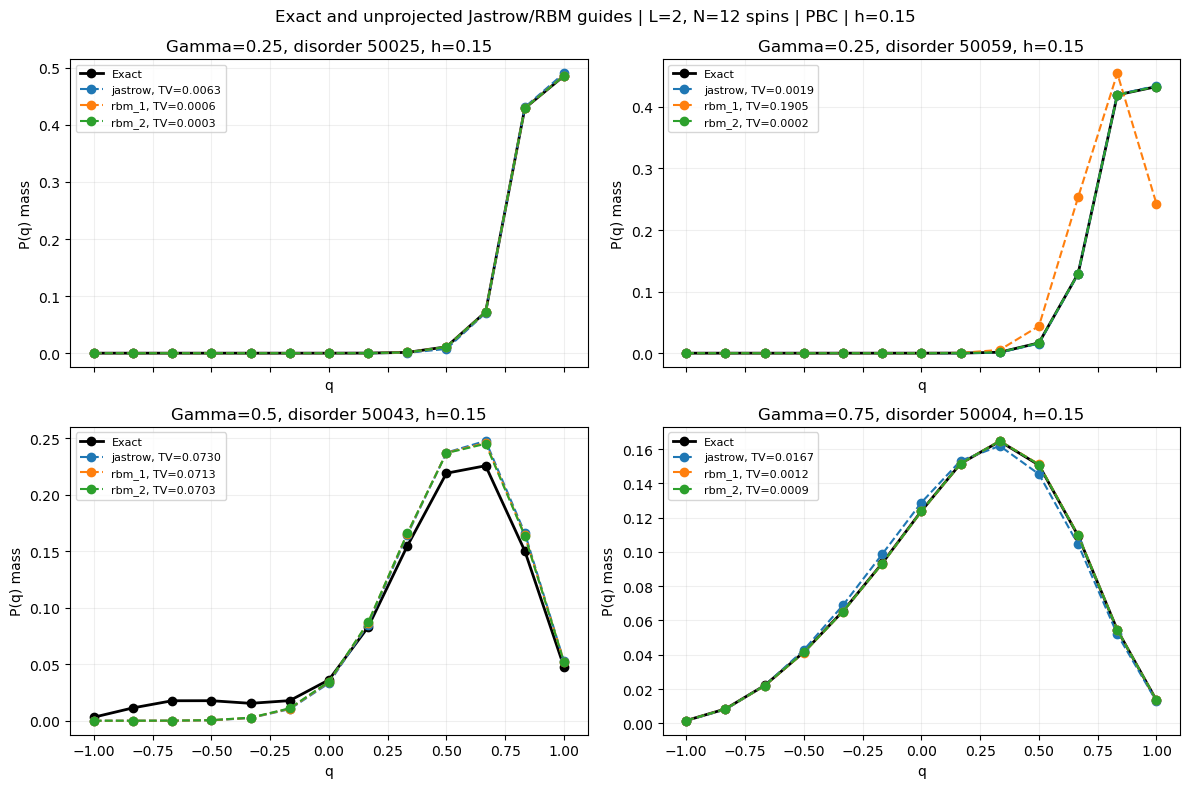

In [9]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
folder=root/'data/kagome/ltfim_simple_overlap_v1'
rows=json.loads((folder/'distributions.json').read_text())['rows']
contexts=[(.25,50025),(.25,50059),(.5,50043),(.75,50004)]
kinds=['jastrow','rbm_1','rbm_2']
figures=root/'figures/simple_overlap';figures.mkdir(parents=True,exist_ok=True)
fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True)
for ax,(g,s) in zip(axes.flat,contexts):
    group=[r for r in rows if (r['gamma'],r['sample_id'])==(g,s)]
    q=np.array(group[0]['q']);ax.plot(q,group[0]['exact_pq'],'ko-',label='Exact',lw=2)
    for kind in kinds:
        r=next(r for r in group if r['kind']==kind and r['selected'])
        ax.plot(q,r['guide_pq'],'o--',label=f"{kind}, TV={r['tv']:.4f}")
    ax.set_title(f'Gamma={g}, disorder {s}, h=0.15');ax.set_xlabel('q');ax.set_ylabel('P(q) mass')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('Exact and unprojected Jastrow/RBM guides | L=2, N=12 spins | PBC | h=0.15')
fig.tight_layout();fig.savefig(figures/'selected_guides_pq.png',dpi=180);fig.savefig(figures/'selected_guides_pq.pdf');plt.show()


## L=2, N=12: All optimization seeds

Faint curves retain every seed, including fits trapped in another sector. A good
selected curve does not imply reliable optimization. These panels show individual
disorders, so no disorder error bars are attached. TV is half the sum of absolute
bin-probability differences from exact and lies between zero and one.


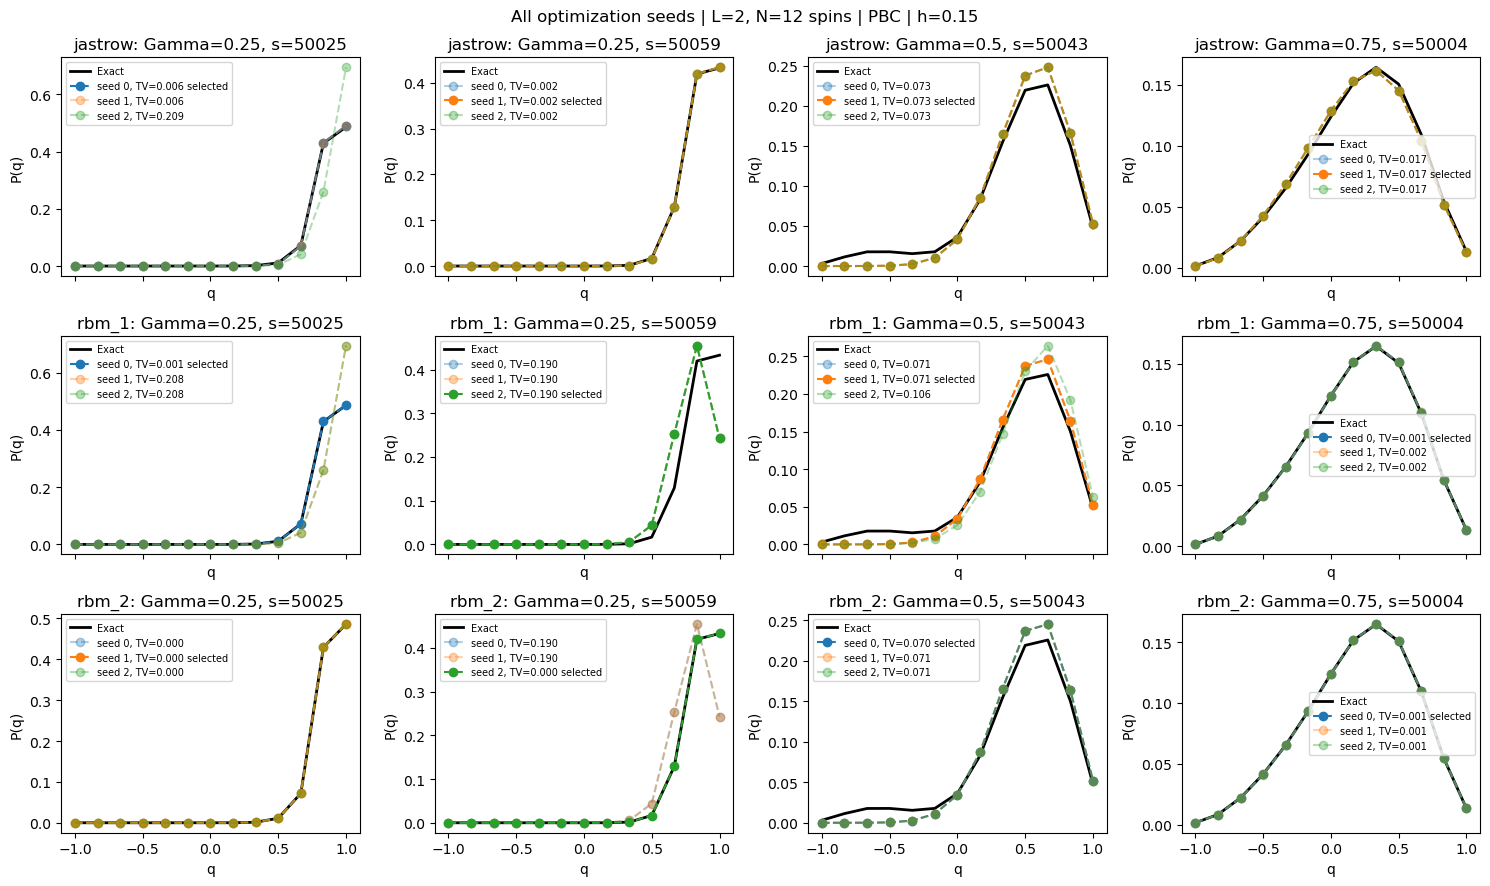

In [10]:
fig,axes=plt.subplots(3,4,figsize=(15,9),sharex=True)
for i,kind in enumerate(kinds):
    for j,(g,s) in enumerate(contexts):
        ax=axes[i,j];group=[r for r in rows if (r['gamma'],r['sample_id'],r['kind'])==(g,s,kind)]
        q=np.array(group[0]['q']);ax.plot(q,group[0]['exact_pq'],'k-',lw=2,label='Exact')
        for r in group:
            ax.plot(q,r['guide_pq'],'o--',alpha=1 if r['selected'] else .35,
                    label=f"seed {r['seed']}, TV={r['tv']:.3f}"+(' selected' if r['selected'] else ''))
        ax.set_title(f'{kind}: Gamma={g}, s={s}');ax.set_xlabel('q');ax.set_ylabel('P(q)');ax.legend(fontsize=7)
fig.suptitle('All optimization seeds | L=2, N=12 spins | PBC | h=0.15')
fig.tight_layout();fig.savefig(figures/'all_seeds_pq.png',dpi=180);fig.savefig(figures/'all_seeds_pq.pdf');plt.show()


## L=2, N=12: Guides learned with sampled VMC

These fits used parallel-tempering samples during training. Each panel shows
both seeds and direct/continuation schedules; no seed is selected. The curves
are computed from frozen guide probabilities after training, using L2-only
enumeration to remove histogram sampling noise. In this original campaign,
continuation used more updates than direct training. A separate matched-update
field campaign addresses that confound.


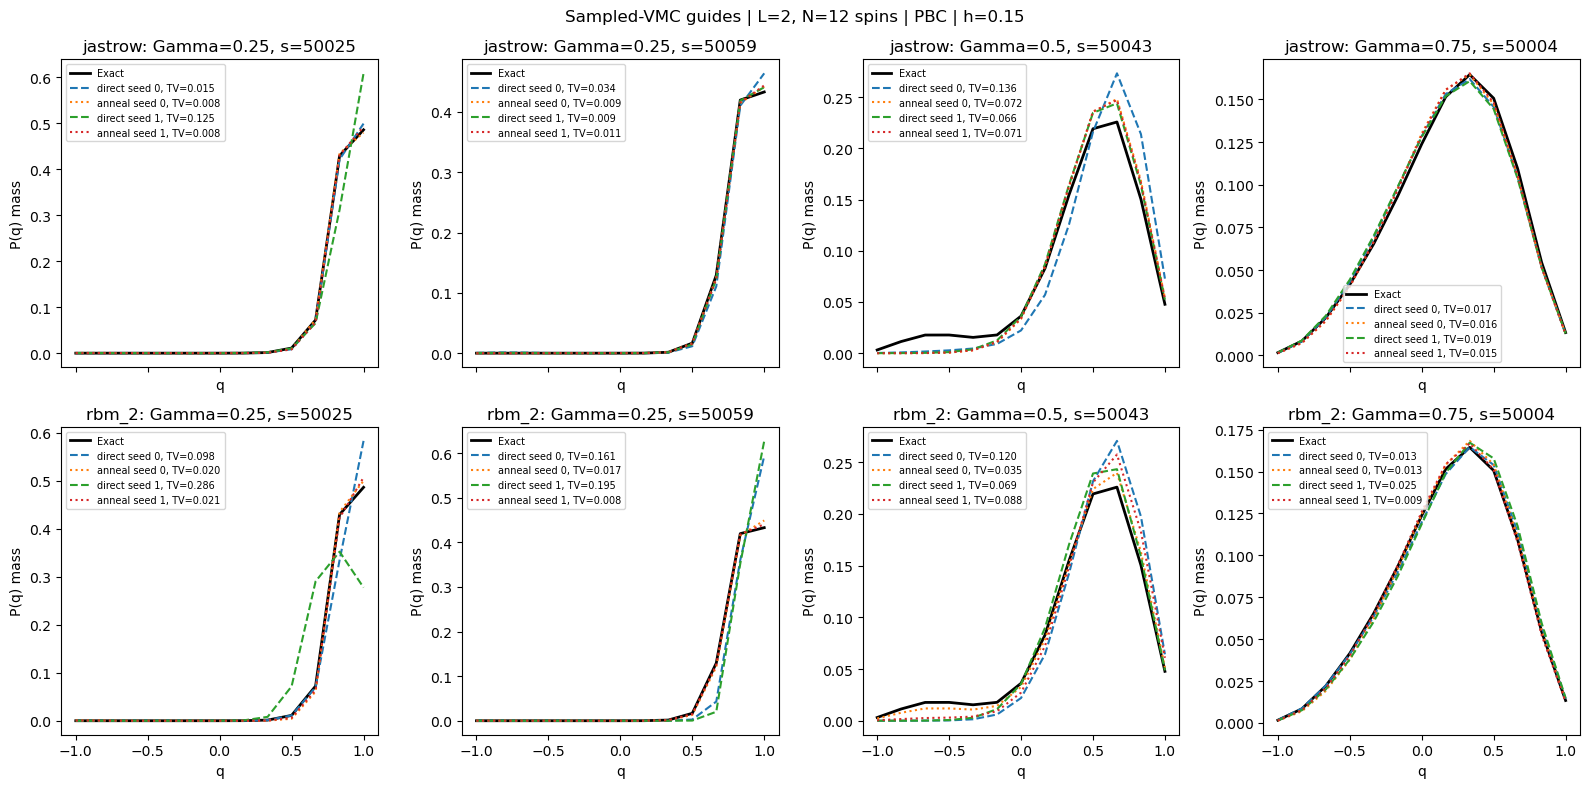

In [11]:
sampled=json.loads((folder/'sampled_distributions.json').read_text())['rows']
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
for i,kind in enumerate(['jastrow','rbm_2']):
    for j,(g,s) in enumerate(contexts):
        ax=axes[i,j];group=[r for r in sampled if (r['kind'],r['gamma'],r['sample_id'])==(kind,g,s)]
        q=np.array(group[0]['q']);ax.plot(q,group[0]['exact_pq'],'k-',lw=2,label='Exact')
        for r in group:
            ax.plot(q,r['guide_pq'],ls='--' if r['mode']=='direct' else ':',
                label=f"{r['mode']} seed {r['seed']}, TV={r['tv']:.3f}")
        ax.set_title(f'{kind}: Gamma={g}, s={s}');ax.set_xlabel('q');ax.set_ylabel('P(q) mass');ax.legend(fontsize=7)
fig.suptitle('Sampled-VMC guides | L=2, N=12 spins | PBC | h=0.15')
fig.tight_layout();fig.savefig(figures/'sampled_guides_pq.png',dpi=180);fig.savefig(figures/'sampled_guides_pq.pdf');plt.show()


## L=2, N=12: Gradually increasing Gamma: physical structure and numerical reliability

Hold $h=0.15$ and each disorder fixed. Fields are 0.50, 0.55, 0.60, 0.65, 0.70,
0.75, 0.85 and 1.00. The eight IDs 50000–50007 form the matched disorder set;
50043 is shown separately as a difficult-case diagnostic. Compute $P_J$ first,
then average across disorders; never pair states from different disorders.
Error bars are one descriptive standard error across disorders, not training
uncertainty or Monte Carlo error.

We track exact overlap variance and gap separately from guide TV, spectral error
and seed reliability. Broad or changing P(q) in L2 is evidence of a finite-size
crossover, not a thermodynamic phase. Convergence failure cannot define a phase.
A candidate field needs both retained physical structure and stable algorithms;
this full-basis fit screen alone cannot qualify GFMC or larger L.


Completed field/disorder contexts: 72 of 72


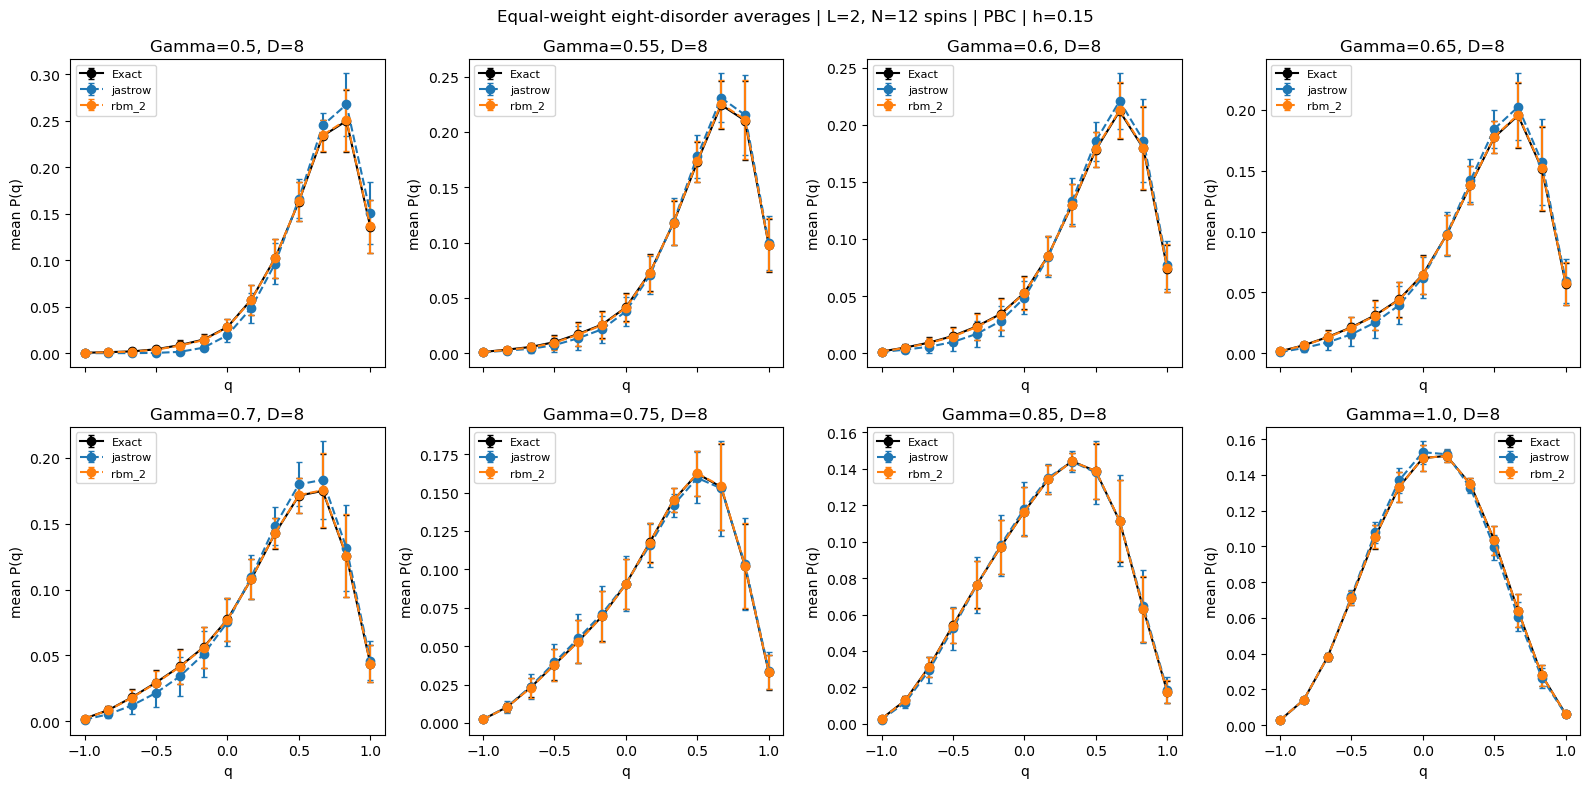

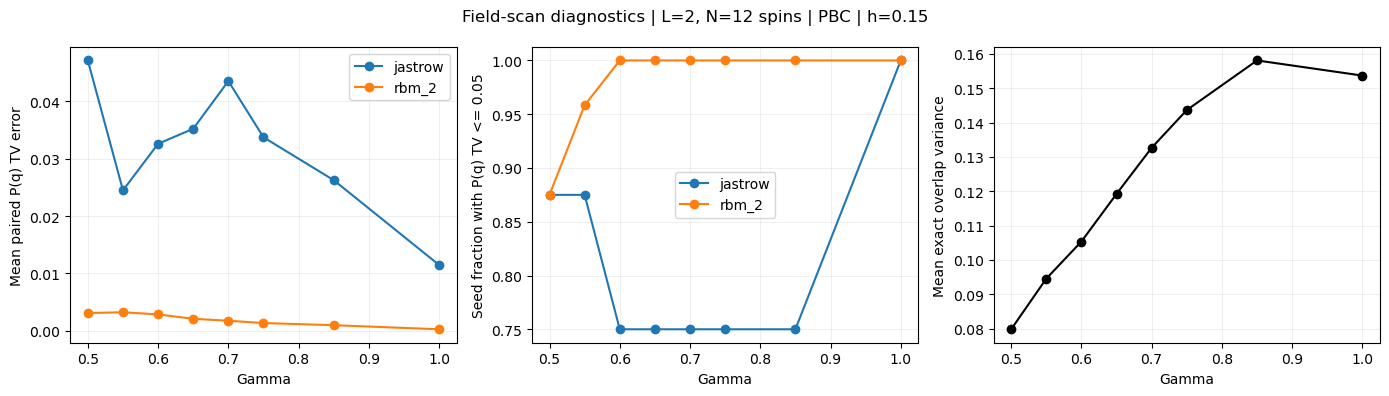

Difficult disorder 50043:
Gamma 0.5 gap 0.028477786317727904 overlap variance 0.1433127878862404 [('jastrow', 0.0729940168535432, 0.2509512905889713), ('rbm_2', 0.0703398412035221, 0.23805360723406227)]
Gamma 0.55 gap 0.03664984971919516 overlap variance 0.18053308687222785 [('jastrow', 0.12068933784073164, 0.3998011282255262), ('rbm_2', 0.030574404546370594, 0.1521805488745425)]
Gamma 0.6 gap 0.04654576047971304 overlap variance 0.21321177882328507 [('jastrow', 0.1810517325668849, 0.5415127524267529), ('rbm_2', 0.006000315449658306, 0.03186724750720627)]
Gamma 0.65 gap 0.059274070733710715 overlap variance 0.23133759145619373 [('jastrow', 0.24257522754388927, 0.6384041075915948), ('rbm_2', 0.0021775489138959173, 0.009376335985721641)]
Gamma 0.7 gap 0.07591076654624018 overlap variance 0.23318165540165128 [('jastrow', 0.0852798718987304, 0.3478271533580209), ('rbm_2', 0.0016126087889206404, 0.0060802336502483526)]
Gamma 0.75 gap 0.09726105403858831 overlap variance 0.2242839480989553 [

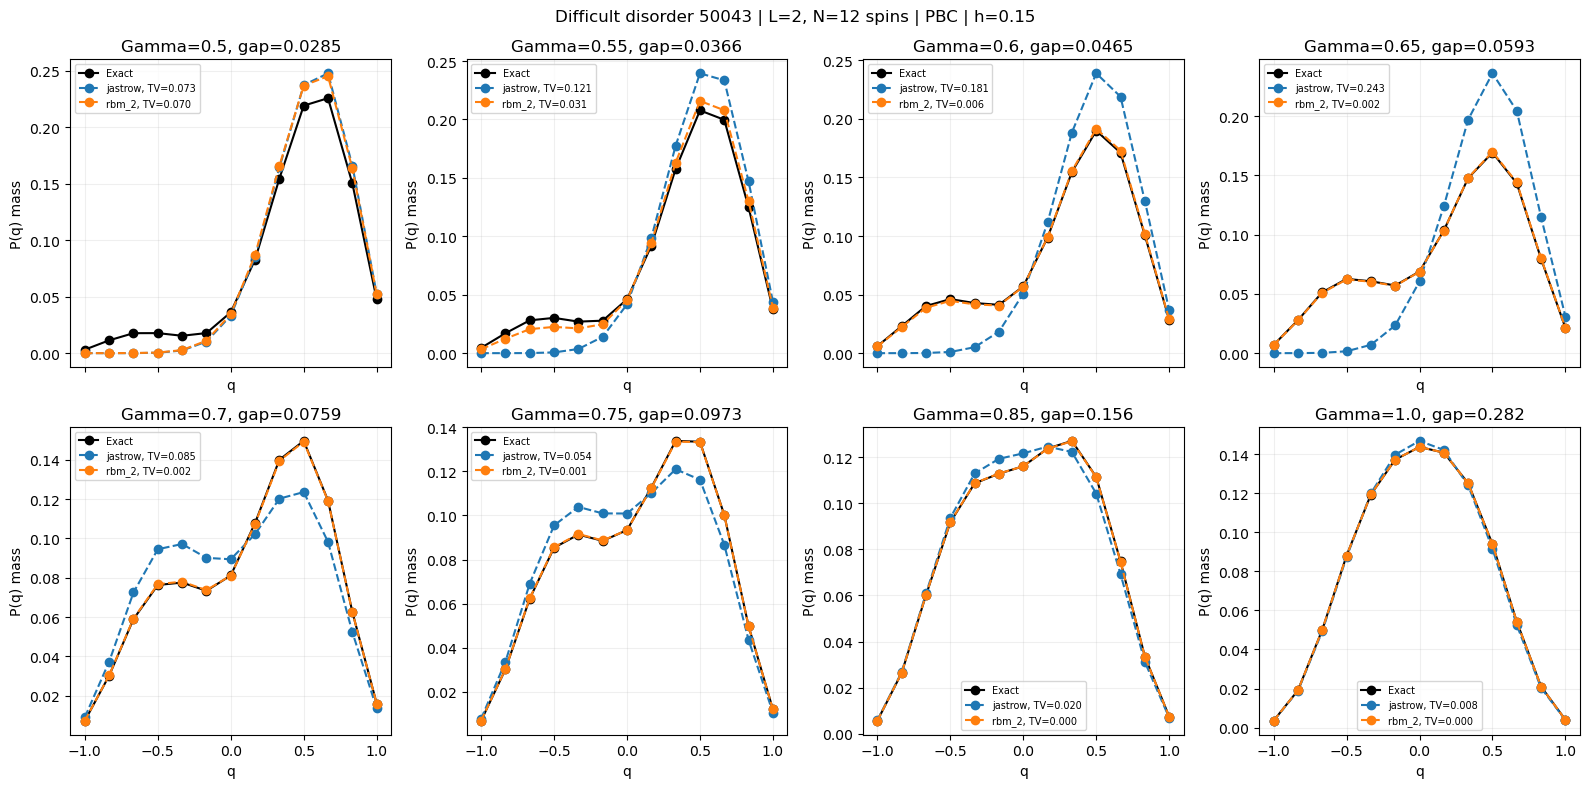

In [12]:
scan=json.loads((folder/'scan_snapshot.json').read_text())
print('Completed field/disorder contexts:',len(scan['rows']),'of 72')
summary=scan['summary'];gammas=sorted(set(r['gamma'] for r in summary))
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
for ax,g in zip(axes.flat,gammas):
    group=[r for r in summary if r['gamma']==g];q=np.linspace(-1,1,13)
    ax.errorbar(q,group[0]['exact_pq'],yerr=group[0]['exact_disorder_se'],fmt='ko-',capsize=2,label='Exact')
    for r in group:
        ax.errorbar(q,r['guide_pq'],yerr=r['guide_disorder_se'],fmt='o--',capsize=2,label=r['kind'])
    ax.set_title(f"Gamma={g}, D={group[0]['disorders']}");ax.set_xlabel('q');ax.set_ylabel('mean P(q)');ax.legend(fontsize=8)
fig.suptitle('Equal-weight eight-disorder averages | L=2, N=12 spins | PBC | h=0.15')
fig.tight_layout();fig.savefig(figures/'field_scan_pq.png',dpi=180);fig.savefig(figures/'field_scan_pq.pdf');plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4))
for kind in ['jastrow','rbm_2']:
    group=sorted([r for r in summary if r['kind']==kind],key=lambda r:r['gamma'])
    x=[r['gamma'] for r in group]
    axes[0].plot(x,[r['mean_paired_tv'] for r in group],'o-',label=kind)
    axes[1].plot(x,[r['seed_fraction_pq_tv_below_005'] for r in group],'o-',label=kind)
group=sorted([r for r in summary if r['kind']=='jastrow'],key=lambda r:r['gamma'])
axes[2].plot([r['gamma'] for r in group],[r['mean_overlap_variance'] for r in group],'ko-')
axes[0].set_ylabel('Mean paired P(q) TV error');axes[1].set_ylabel('Seed fraction with P(q) TV <= 0.05')
axes[2].set_ylabel('Mean exact overlap variance')
for ax in axes:ax.set_xlabel('Gamma');ax.grid(alpha=.2)
axes[0].legend();axes[1].legend()
fig.suptitle('Field-scan diagnostics | L=2, N=12 spins | PBC | h=0.15')
fig.tight_layout()
fig.savefig(figures/'field_scan_tradeoff.png',dpi=180);fig.savefig(figures/'field_scan_tradeoff.pdf');plt.show()
print('Difficult disorder 50043:')
for r in sorted([r for r in scan['rows'] if r['sample_id']==50043],key=lambda r:r['gamma']):
    print('Gamma',r['gamma'],'gap',r['exact']['gap'],'overlap variance',r['exact']['variance'],
          [(f['kind'],f['pq_tv'],f['max_spectral_error']) for f in r['fits'] if f['selected']])
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
hard=sorted([r for r in scan['rows'] if r['sample_id']==50043],key=lambda r:r['gamma'])
for ax,r in zip(axes.flat,hard):
    q=np.array(r['exact']['q']);ax.plot(q,r['exact']['pq'],'ko-',label='Exact')
    for f in r['fits']:
        if f['selected']:ax.plot(q,f['pq'],'o--',label=f"{f['kind']}, TV={f['pq_tv']:.3f}")
    ax.set_title(f"Gamma={r['gamma']}, gap={r['exact']['gap']:.3g}")
    ax.set_xlabel('q');ax.set_ylabel('P(q) mass');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle('Difficult disorder 50043 | L=2, N=12 spins | PBC | h=0.15')
fig.tight_layout();fig.savefig(figures/'difficult_disorder_scan.png',dpi=180)
fig.savefig(figures/'difficult_disorder_scan.pdf');plt.show()


## L=2, N=12: Candidate field region

The completed full-basis screen identifies **$\Gamma=0.60$–$0.70$ as an RBM
candidate window**. On disorder 50043 the exact negative-overlap shoulder grows
through this interval while the selected RBM TV error falls from 0.0060 to
0.0016. At $\Gamma=0.65$, TV is 0.0022 and connected-spectrum error is 0.94%.
All three RBM seeds on this disorder have TV below 0.01 from 0.60 onward. Across
the separate eight-disorder ensemble, all 24 RBM seeds have TV below 0.05 from
0.60 onward. These descriptive thresholds do not certify ground-state sampling.

Jastrow remains unreliable here: its selected TV on 50043 rises to 0.243 at
0.65. The apparent window is therefore ansatz-dependent. Negative-overlap weight
alone is not a phase identifier; it can also rise as a distribution approaches
a symmetric paramagnet. The shoulder and two maxima in this small system are
features to follow with size, not evidence of thermodynamic replica symmetry
breaking.

Two independent follow-ups have been launched on AutoDL: equal-update sampled
VMC at $L=2,4$ (1200 updates per fit, direct versus continuation), and CT GFMC
population/time sensitivity over all eight fields. Their live records are under
`data/kagome/ltfim_simple_overlap_v1/sampled/` and `projector/`. This notebook's
field recommendation is based on the completed full-basis screen; it does not
claim those follow-ups have converged.


## Saved disorder averages: sizes, Hamiltonian and provenance

The following results are frozen measurements from the completed companion reports. Snapshot dates and ensemble coverage are printed by the loading cells. They are not a live campaign status.

**Sizes: L=2, N=12 and L=4, N=48; periodic boundaries; h=0.15.**

### Shared protocol

 Periodic kagome nearest-neighbor bonds
are generated once per disorder sample, with
$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-h\sum_i Z_i-\Gamma\sum_i X_i,
\qquad K_{ij}=1+0.5u_{ij},\quad u_{ij}\overset{\mathrm{iid}}\sim U(-1,1).$$
Thus $K_{ij}\sim U(0.5,1.5)$, independently on each undirected nearest-neighbor
edge; all bonds are antiferromagnetic and their mean strength sets the energy
unit. Frustration comes from kagome geometry. The implementation stores
$J_{ij}=-K_{ij}$ in the equivalent convention $-\sum J_{ij}Z_iZ_j$.
For reproducibility, NumPy `default_rng(SeedSequence([20261027, L, sample_id, 1]))`
draws one uniform variate per bond in the lattice bond-list order; the final
`1` specifies periodic boundaries. These are quenched couplings: the same bonds
are held fixed through training, MC and projection, across both guide families,
all seeds and every $\Gamma$ for a given $(L,\mathrm{sample\_id})$.
$L=2$ uses IDs 50000–50007 and $L=4$ uses 60000–60007. Different sizes have
different bond realizations, even if an ID is reused. Couplings are never
selected or reweighted by the observed shape of $P(q)$.

Only disorder averages are shown at $\Gamma=0.60,0.65$. The $L=2$ panels overlay
exact guide, exact ground-state, and available MC/GFMC curves; $L=4$ uses
**before projection** and **after projection** columns.
Each curve gives equal weight to eight disorders.
**Capped error bars are $\pm1$ standard error of the disorder mean**
($s_J/\sqrt{8}$), pointwise in $q$. They describe finite-ensemble variation and
do not bound mixing, finite-population or finite-forward-time errors.

$q=N^{-1}\sum_i s_i t_i$ uses independent physical replicas of the same disorder.
$P(q)$ is probability mass per allowed overlap; connecting lines are visual aids.
The next two figures show $L=2$ with exact and Monte Carlo comparisons, then $L=4$.
All outputs were computed and executed on AutoDL.

In [13]:
%matplotlib inline
from pathlib import Path
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
folder=root/'data/kagome/ltfim_disorder_scaling_v1/notebook_snapshot/20261103T031619Z_compact_complete'
load=lambda name: json.loads((folder/name).read_text())
guides=load('guide_distributions.json')['rows']
l2=load('guide_distributions_l2.json')['rows']
projected=load('projected_distributions.json')['rows']
exact=load('exact_l2_reference.json')['rows']
if (folder/'interim_snapshot.json').exists():
    frozen=load('interim_snapshot.json')
    for name,digest in frozen['input_sha256'].items():
        assert hashlib.sha256((folder/name).read_bytes()).hexdigest()==digest
    print('Histogram inputs frozen at:',frozen['created_utc'])
assert load('manifest.json')['h']==.15
assert all(r['h']==.15 for r in exact)
allow_pending=False
if not allow_pending:
    complete=load('histogram_complete.json')
    assert complete['projected']==128 and complete['sampled']==32 and not complete['failures']
    assert len(projected)==128 and len(l2)==32
assert all(r['replay_verified'] for r in projected if r['task']['L']==4)
figures=root/'figures/simple_overlap'; figures.mkdir(exist_ok=True)
colors={'jastrow':'tab:blue','rbm_2':'tab:orange'}
names={'jastrow':'Jastrow','rbm_2':'RBM (alpha=2)'}
def mean_se(values):
    a=np.asarray(values,dtype=float)
    assert len(a)==8
    np.testing.assert_allclose(a.sum(1),1,atol=1e-12)
    return a.mean(0),a.std(0,ddof=1)/np.sqrt(len(a))
def curve(ax,q,values,label,color,fmt='o-',alpha=1):
    if q is None:
        ax.text(.03,.96-.065*len(ax.texts),label+' pending (complete ensemble required)',
                transform=ax.transAxes,va='top',fontsize=7,color=color)
        return
    mean,se=mean_se(values)
    ax.errorbar(q,mean,yerr=se,fmt=fmt,color=color,ms=3,lw=1.15,
                elinewidth=.75,capsize=2,capthick=.75,label=label,alpha=alpha)
def guide_group(rows,L,g,kind):
    group=[r for r in rows if r['task']['L']==L and r['task']['gamma']==g
           and r['task']['kind']==kind and r.get('selected',True)]
    group=sorted(group,key=lambda r:r['task']['sample_id'])
    if allow_pending and len(group)!=8:
        return None,None
    assert len(group)==8 and len({r['task']['sample_id'] for r in group})==8
    return np.array(group[0]['q_grid']),np.array([np.mean([s['mass'] for s in r['starts']],axis=0) for r in group])
def projected_group(L,g,kind):
    group=[r for r in projected if (r['task']['L'],r['task']['gamma'],r['task']['kind'])==(L,g,kind)]
    ids=sorted({r['task']['sample_id'] for r in group})
    if allow_pending and (len(group)!=16 or len(ids)!=8):
        return None,None
    assert len(group)==16 and len(ids)==8
    values=[]
    for sid in ids:
        rs=[r for r in group if r['task']['sample_id']==sid]
        assert {r['task']['repeat'] for r in rs}=={0,1}
        values.append(np.mean([r['mass'] for r in rs],axis=0))
    return np.array(group[0]['q_grid']),np.array(values)
def finish(fig,name):
    fig.tight_layout()
    fig.savefig(figures/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(figures/(name+'.pdf'),bbox_inches='tight')
    plt.show()
def axes_style(axes):
    for ax in axes.flat:
        ax.set(xlabel='q',ylabel='Disorder mean P(q) mass',xlim=(-1.03,1.03))
        ax.grid(alpha=.2); ax.legend(fontsize=8)
print('Frozen L=4 production snapshot:',load('snapshot.json')['created_utc'])
print('Chosen longitudinal field: h=0.15 (fixed); transverse fields: Gamma=0.60, 0.65.')
print(f'Completed histogram measurements: {len(projected)}/128 GFMC runs and {len(l2)}/32 L=2 guide MC tasks; eight disorders per plotted curve.')
for L in [2,4]:
    for g in [.6,.65]:
        for kind in ['jastrow','rbm_2']:
            before=guide_group(l2 if L==2 else guides,L,g,kind)[0] is not None
            after=projected_group(L,g,kind)[0] is not None
            print(f'L={L}, Gamma={g:.2f}, {names[kind]}: before MC {"complete" if before else "pending"}; after GFMC {"complete" if after else "pending"}')


Histogram inputs frozen at: 20261103T031619Z
Frozen L=4 production snapshot: 20261103T021444Z
Chosen longitudinal field: h=0.15 (fixed); transverse fields: Gamma=0.60, 0.65.
Completed histogram measurements: 128/128 GFMC runs and 32/32 L=2 guide MC tasks; eight disorders per plotted curve.
L=2, Gamma=0.60, Jastrow: before MC complete; after GFMC complete
L=2, Gamma=0.60, RBM (alpha=2): before MC complete; after GFMC complete
L=2, Gamma=0.65, Jastrow: before MC complete; after GFMC complete
L=2, Gamma=0.65, RBM (alpha=2): before MC complete; after GFMC complete
L=4, Gamma=0.60, Jastrow: before MC complete; after GFMC complete
L=4, Gamma=0.60, RBM (alpha=2): before MC complete; after GFMC complete
L=4, Gamma=0.65, Jastrow: before MC complete; after GFMC complete
L=4, Gamma=0.65, RBM (alpha=2): before MC complete; after GFMC complete


## L=2, N=12: exact guides, ground state, MCMC and GFMC

**$L=2$: all comparisons on the same axes.** Each panel overlays exact
enumeration of the trained Jastrow and RBM guide distributions (colored dashed
curves with triangle markers), the exact ground-state distribution (black squares),
and available guide MCMC (colored dots without connecting lines) and pure GFMC
estimates (colored solid curves with circles). One panel is shown per $\Gamma$.
All curves use disorder IDs 50000–50007. The two guide families use their
previously selected energy-trained fits. MC starts and repeats are averaged
within each disorder before computing the disorder mean and its error bars.

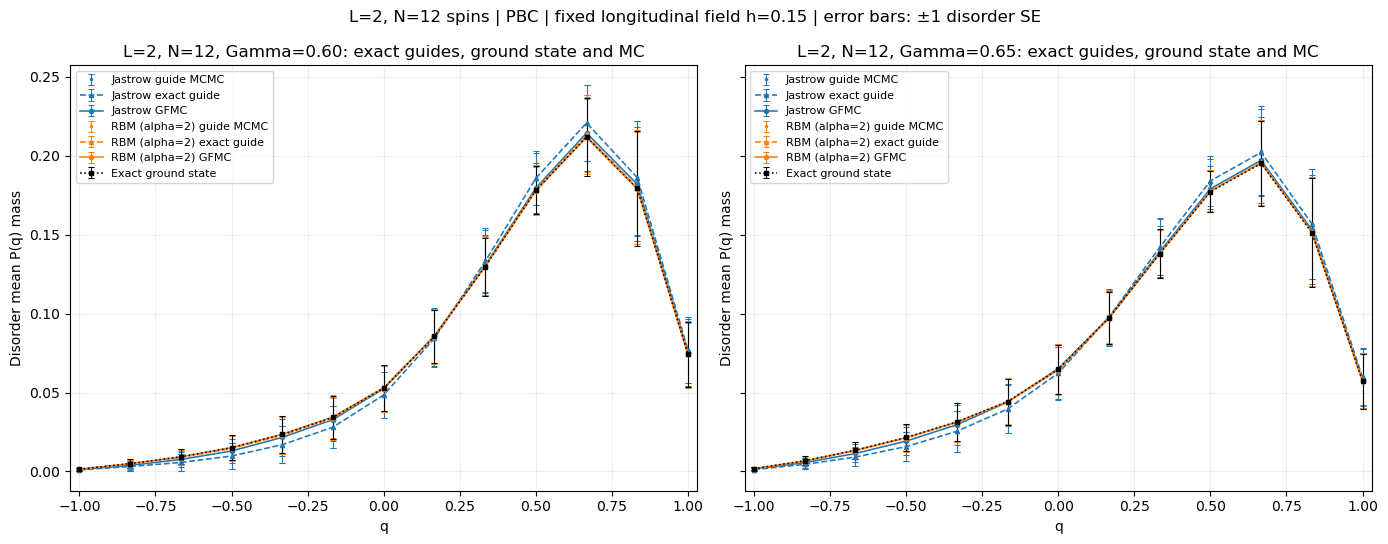

In [14]:
fig,axes=plt.subplots(1,2,figsize=(14,5.5),sharex=True,sharey=True)
for ax,g in zip(axes,[.6,.65]):
    reference=sorted([r for r in exact if r['gamma']==g and r['sample_id'] in range(50000,50008)],key=lambda r:r['sample_id'])
    assert [r['sample_id'] for r in reference]==list(range(50000,50008))
    q=np.array(reference[0]['exact']['q'])
    for kind in ['jastrow','rbm_2']:
        grid,values=guide_group(l2,2,g,kind)
        curve(ax,grid,values,names[kind]+' guide MCMC',colors[kind],fmt='.')
        enumerated=[next(f['pq'] for f in r['fits'] if f['kind']==kind and f['selected']) for r in reference]
        curve(ax,q,enumerated,names[kind]+' exact guide',colors[kind],fmt='^--')
        grid,values=projected_group(2,g,kind)
        curve(ax,grid,values,names[kind]+' GFMC',colors[kind])
    curve(ax,q,[r['exact']['pq'] for r in reference],'Exact ground state','black',fmt='s:')
    ax.set_title(f'L=2, N=12, Gamma={g:.2f}: exact guides, ground state and MC')
axes_style(axes)
fig.suptitle('L=2, N=12 spins | PBC | fixed longitudinal field h=0.15 | error bars: ±1 disorder SE',fontsize=12)
finish(fig,'disorder_mean_l2_overlay')


## L=4, N=48: before and after projection

**4 × 4 unit cells, three spins per cell, periodic boundaries in both directions.** There are 49 allowed overlaps with spacing 1/24.

**$L=4$: before and after projection.** Both columns use disorder IDs
60000–60007 and the same selected frozen guides. Before projection uses MCMC
with random/up/down starts. After projection uses four independently branching
populations with descendant-weighted tagged configurations, 512 walkers per
population, equilibration and forward times 16, eight cycles and two repeats.
The histograms replay the frozen production trajectories; their first and
second moments and connected spectra match those original records to $10^{-12}$.
The $L=2$ and $L=4$ disorder ensembles are different.

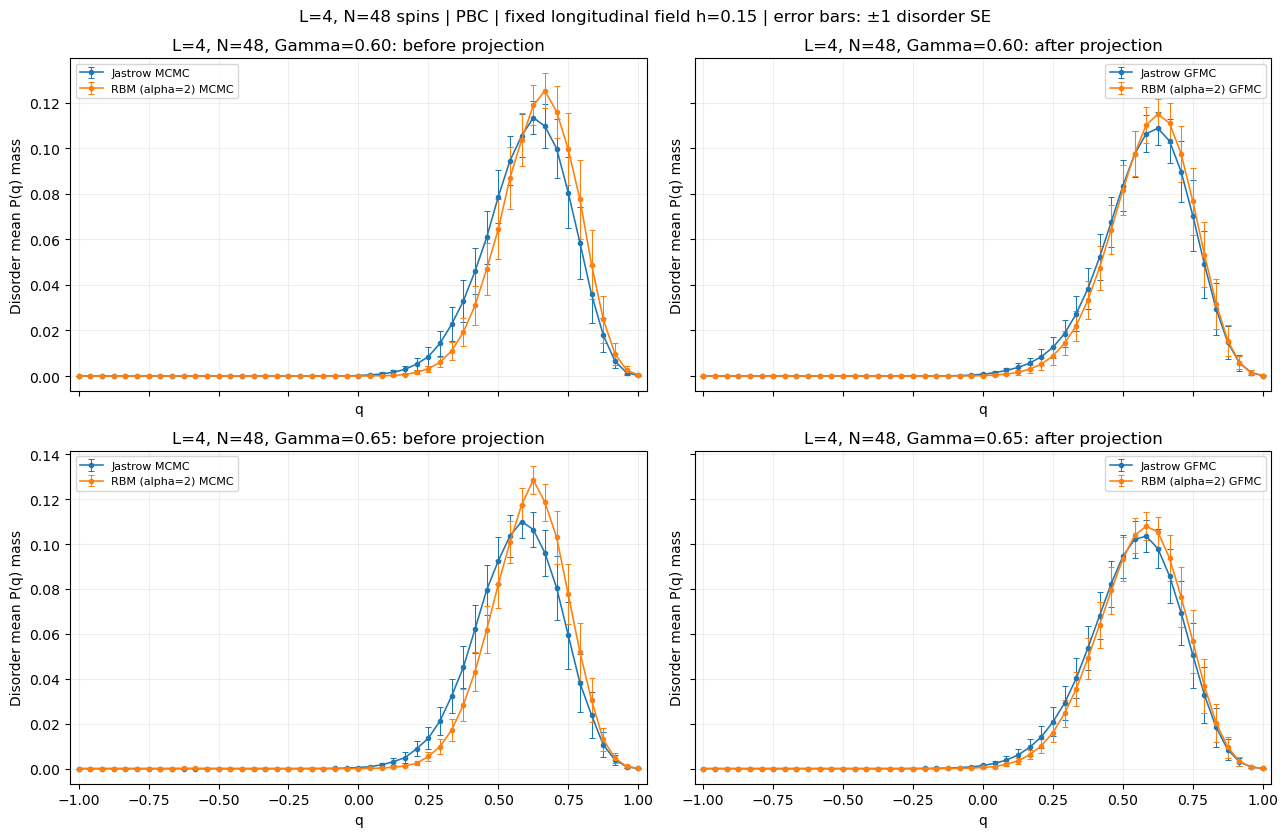

In [15]:
fig,axes=plt.subplots(2,2,figsize=(13,8.5),sharex=True,sharey='row')
for row,g in enumerate([.6,.65]):
    for kind in ['jastrow','rbm_2']:
        grid,values=guide_group(guides,4,g,kind)
        curve(axes[row,0],grid,values,names[kind]+' MCMC',colors[kind])
        grid,values=projected_group(4,g,kind)
        curve(axes[row,1],grid,values,names[kind]+' GFMC',colors[kind])
    axes[row,0].set_title(f'L=4, N=48, Gamma={g:.2f}: before projection')
    axes[row,1].set_title(f'L=4, N=48, Gamma={g:.2f}: after projection')
axes_style(axes)
fig.suptitle('L=4, N=48 spins | PBC | fixed longitudinal field h=0.15 | error bars: ±1 disorder SE',fontsize=12)
finish(fig,'disorder_mean_l4_before_after')


In [16]:
# Integrity checks and a compact numerical audit; no individual-disorder plots.
for r in projected+l2+guides:
    assert hashlib.sha256((folder/r['raw_file']).read_bytes()).hexdigest()==r['raw_sha256']
for r in projected:
    p=np.array(r['mass']); q=np.array(r['q_grid'])
    assert np.all(p>=0) and np.isclose(p.sum(),1)
    np.testing.assert_allclose([q@p,q**2@p],[r['q'],r['q2']],atol=1e-12)
rows=[]
for L in [2,4]:
    for g in [.6,.65]:
        for kind in ['jastrow','rbm_2']:
            q,p=projected_group(L,g,kind)
            if q is None:
                continue
            rs=[r for r in projected if (r['task']['L'],r['task']['gamma'],r['task']['kind'])==(L,g,kind)]
            mean=p.mean(0)
            sample_means=p@q
            within_variance=float(np.mean(p@(q*q)-sample_means**2))
            between_variance=float(np.var(sample_means))
            np.testing.assert_allclose(within_variance+between_variance,q**2@mean-(q@mean)**2,atol=1e-12)
            magnetizations=[]
            for r in rs:
                with np.load(folder/r['raw_file']) as data:
                    spin_mean=data['tags'].mean(3)
                    magnetizations.append(float((data['counts']/r['task']['walkers']*spin_mean).sum(2).mean()))
            tv='—'
            if L==2:
                truth=np.mean([r['exact']['pq'] for r in exact if r['gamma']==g and r['sample_id'] in range(50000,50008)],axis=0)
                tv=f'{np.abs(mean-truth).sum()/2:.4f}'
            rows.append([L,g,names[kind],f'{q@mean:.5f}',f'{np.sqrt(q**2@mean-(q@mean)**2):.4f}',
                         f'{within_variance:.5f}',f'{between_variance:.5f}',
                         f'{np.mean(magnetizations):.4f}',f'{mean[q<0].sum():.5f}',
                         tv,f"{sum(r['ancestry_alarm'] for r in rs)}/16"])
headers=['L','Gamma','Guide','Projected mean q','Width sigma(q)','Within-disorder variance','Between-disorder variance','Uniform m','P(q<0)','TV to exact mean','Ancestry alarms']
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join(map(str,row))+' |' for row in rows)))
print('Raw histogram hashes and moment identities verified. Data:',folder)


| L | Gamma | Guide | Projected mean q | Width sigma(q) | Within-disorder variance | Between-disorder variance | Uniform m | P(q<0) | TV to exact mean | Ancestry alarms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2 | 0.6 | Jastrow | 0.48912 | 0.3651 | 0.09757 | 0.03573 | 0.1059 | 0.07987 | 0.0090 | 2/16 |
| 2 | 0.6 | RBM (alpha=2) | 0.47827 | 0.3759 | 0.10495 | 0.03639 | 0.1060 | 0.08860 | 0.0009 | 0/16 |
| 2 | 0.65 | Jastrow | 0.42855 | 0.3882 | 0.11061 | 0.04012 | 0.0976 | 0.11108 | 0.0080 | 2/16 |
| 2 | 0.65 | RBM (alpha=2) | 0.42041 | 0.3969 | 0.11863 | 0.03889 | 0.0972 | 0.11848 | 0.0013 | 0/16 |
| 4 | 0.6 | Jastrow | 0.58095 | 0.1567 | 0.01914 | 0.00542 | 0.0690 | 0.00074 | — | 6/16 |
| 4 | 0.6 | RBM (alpha=2) | 0.59730 | 0.1453 | 0.01690 | 0.00421 | 0.0677 | 0.00014 | — | 8/16 |
| 4 | 0.65 | Jastrow | 0.53933 | 0.1625 | 0.02040 | 0.00600 | 0.0660 | 0.00160 | — | 5/16 |
| 4 | 0.65 | RBM (alpha=2) | 0.55709 | 0.1532 | 0.01927 | 0.00421 | 0.0642 | 0.00043 | — | 14/16 |

Raw histogram hashes and moment identities verified. Data: /Users/tianyiyan/Dropbox/spin-glasses/data/kagome/ltfim_disorder_scaling_v1/notebook_snapshot/20261103T031619Z_compact_complete


All disorder samples, seeds, starts, repeats and ancestry alarms remain
in the accompanying data. Alarmed runs retain equal disorder weight. Projection
results remain preliminary: agreement with $L=2$ exact data does not qualify
$L=4$ population or forward-time convergence. Complete matched $L=6$ histograms
are not yet available in this snapshot. No crossing or collapse is inferred.

## L=4, N=48: higher-field distributions

These are measured pure GFMC overlap histograms for periodic kagome $L=4$
($N=48$). Only complete ensembles with eight disorders and two repeats per
disorder are shown. The same disorder IDs 60000–60007 have equal weight at every
field and for both guides; no disorder is selected by its observed broadness.
The exact $L=2$ and guide-MCMC comparisons are included earlier in this notebook.

The Hamiltonian is
$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-0.15\sum_iZ_i-\Gamma\sum_iX_i,$$
with iid antiferromagnetic bonds $K_{ij}\sim U(0.5,1.5)$, stored as $J_{ij}=-K_{ij}$.
NumPy `default_rng(SeedSequence([20261027,L,sample_id,1]))` draws bonds in the
periodic lattice bond-list order. Quenched bonds are reused across all fields,
guides, and seeds for each size and disorder ID.

Each run uses four independently branching populations with 512 walkers each,
equilibration and forward times 16, and eight cycles. Descendant-weighted
configurations are pooled equally across cycles; all six cross-population pairs
give $q=N^{-1}\sum_i s_i t_i$. Repeats are averaged within each disorder first.
The higher-field histograms are deterministic replays of frozen production
trajectories. Their $q,q^2$, and connected spectra must match production to
$10^{-12}$. The $\Gamma=0.60,0.65$ histograms reuse the earlier verified measurements.

$P(q)$ denotes probability mass at each allowed overlap; connecting lines are
visual aids. Capped bars give $\pm s_J/\sqrt8$ pointwise in $q$. Width bars use a
delete-one-disorder jackknife. These errors exclude mixing and projection bias.
All ancestry alarms retain equal disorder weight. **The projections remain
preliminary** pending population, forward-time and starting-state sensitivity.
Broadening alone does not establish glassiness, a transition, or finite-size drift.
Computation, checks, plotting and notebook execution take place on AutoDL.

In [18]:
%matplotlib inline
from pathlib import Path
import hashlib, json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
broader_folder=root/'data/kagome/ltfim_disorder_scaling_v1/broader_histograms/20261103T035100Z_preview'
# NumPy-only report helpers, copied unchanged from this frozen snapshot.
# Importing the training package pulls in PyTorch, which plotting does not need.
from itertools import combinations

def broader_canonical(value):
    return json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False)

def broader_identity(value):
    return hashlib.sha256(broader_canonical(value).encode()).hexdigest()

def broader_geometry(L):
    """Triangular cell reciprocal vectors and all allowed cell momenta.

Lattice indexing is (cell y, cell x, sublattice). Fourier arrays use the
same (my, mx) order. Connected kmin averages directions b1,b2,b1+b2.
"""
    cell = np.array([[2., 1.], [0., np.sqrt(3)]])
    reciprocal = 2*np.pi*np.linalg.inv(cell).T
    indices = np.array([(mx, my) for my in range(L) for mx in range(L)])
    momenta = indices @ reciprocal.T / L
    positions = np.array([[0., 0.], [1., 0.], [.5, np.sqrt(3)/2]])
    phases = np.exp(-1j*(momenta @ positions.T))
    return dict(L=L, reciprocal=reciprocal, momenta=momenta,
                indices=indices, phases=phases, kmin_indices=[1, L, L+1])

def broader_cross_connected(magnetization, pair):
    """Symmetrize three disjoint pairings, each with expectation C_ij squared."""
    m, q = np.asarray(magnetization), np.asarray(pair)
    if m.ndim != 2 or m.shape[0] != 4 or q.shape != (4, m.shape[1], m.shape[1]):
        raise ValueError('Expected four independent moment estimates')
    def covariance(a, b):
        return .5 * (q[a] + q[b] - np.outer(m[a], m[b]) - np.outer(m[b], m[a]))
    return sum(covariance(a, b) * covariance(c, d)
               for a, b, c, d in [(0, 1, 2, 3), (0, 2, 1, 3), (0, 3, 1, 2)]) / 3

def broader_spectrum_from_moments(magnetization, pair, lattice):
    L = lattice['L']
    cells = np.array([[2*x+y, np.sqrt(3)*y] for y in range(L) for x in range(L)])
    offsets = np.array([[0., 0.], [1., 0.], [.5, np.sqrt(3)/2]])
    points = (cells[:, None] + offsets[None]).reshape(3*L*L, 2)
    phases = np.exp(-1j * (points @ lattice['momenta'].T))
    squared = broader_cross_connected(magnetization, pair)
    return np.einsum('ik,ij,jk->k', phases, squared, phases.conj()).real / len(points)

def broader_observables(m,p,L):
    """Products involve distinct physical populations, including q and q2."""
    pairs=list(combinations(range(4),2))
    q=np.mean([np.mean(m[a]*m[b]) for a,b in pairs])
    q2=np.mean([np.mean(p[a]*p[b]) for a,b in pairs])
    lattice=broader_geometry(L)
    spectrum=broader_spectrum_from_moments(m,p,lattice)[[0]+lattice['kmin_indices']]
    return dict(q=float(q),q2=float(q2),spectrum=spectrum.tolist())
broader_load=lambda name:json.loads((broader_folder/name).read_text())
broader_protocol=broader_load('protocol.json')
assert broader_protocol['h']==.15 and not broader_load('complete.json')['failures']
for name,expected in broader_protocol['input_sha256'].items():
    assert hashlib.sha256((broader_folder/name).read_bytes()).hexdigest()==expected,name
broader_rows=broader_load('projected_distributions.json')['rows']
assert len(broader_rows)==broader_load('complete.json')['projected']
broader_groups=defaultdict(list)
for r in broader_rows:
    t=r['task']; assert t['L']==4 and t['audit']=='main' and r['replay_verified']
    q=np.array(r['q_grid']);p=np.array(r['mass'])
    assert (p>=0).all()
    np.testing.assert_allclose(p.sum(),1,atol=1e-12)
    np.testing.assert_allclose([q@p,q**2@p],[r['q'],r['q2']],atol=1e-12,rtol=0)
    original=broader_load('production/runs/'+broader_identity(t)[:24]+'.json')
    np.testing.assert_allclose([r['q'],r['q2']],[original['q'],original['q2']],atol=1e-12,rtol=0)
    np.testing.assert_allclose(r['spectrum'],original['spectrum'],atol=1e-12,rtol=0)
    assert r['provenance']['model_sha256']==original['provenance']['model_sha256']
    assert hashlib.sha256((broader_folder/r['raw_file']).read_bytes()).hexdigest()==r['raw_sha256']
    with np.load(broader_folder/r['raw_file']) as raw:
        weights=raw['counts']/t['walkers']
        r['uniform_m']=float((weights*raw['tags'].mean(3)).sum(2).mean())
        spins=raw['tags'].astype(float)
        m=np.einsum('crw,crwn->crn',weights,spins)
        pair=np.einsum('crw,crwi,crwj->crij',weights,spins,spins)
        reconstructed=broader_observables(m.mean(0),pair.mean(0),t['L'])
        np.testing.assert_allclose([q@p,q**2@p],[reconstructed['q'],reconstructed['q2']],atol=1e-12,rtol=0)
        np.testing.assert_allclose(r['spectrum'],reconstructed['spectrum'],atol=1e-12,rtol=0)
    broader_groups[(t['gamma'],t['kind'])].append(r)
def broader_width(a):
    mean=a.mean(0)
    return np.sqrt(max(0,float(q*q@mean-(q@mean)**2)))
def broader_jackknife(a,stat):
    x=np.array([stat(np.delete(a,i,axis=0)) for i in range(8)])
    return float(np.sqrt(7/8*np.sum((x-x.mean())**2)))
broader_curves={};broader_summary=[]
for (g,kind),rs in sorted(broader_groups.items()):
    assert len(rs)==16
    byid={sid:[r for r in rs if r['task']['sample_id']==sid] for sid in range(60000,60008)}
    assert all(sorted(r['task']['repeat'] for r in sample)==[0,1] for sample in byid.values())
    values=np.array([np.mean([r['mass'] for r in sample],axis=0) for sample in byid.values()])
    magnet=np.array([np.mean([r['uniform_m'] for r in sample]) for sample in byid.values()])
    q=np.array(rs[0]['q_grid']);mean=values.mean(0);se=values.std(0,ddof=1)/np.sqrt(8)
    assert all(np.array_equal(q,r['q_grid']) for r in rs)
    broader_curves[(g,kind)]=(q,values,mean,se)
    m=values@q;v=values@(q*q)-m*m
    within=float(v.mean());between=float(m.var())
    np.testing.assert_allclose(within+between,broader_width(values)**2,atol=1e-12)
    negative=values[:,q<0].sum(1)
    broader_summary.append(dict(L=4,gamma=g,kind=kind,width=float(broader_width(values)),width_se=broader_jackknife(values,broader_width),
        mean_q=float(m.mean()),mean_q_se=float(m.std(ddof=1)/np.sqrt(8)),peak_q=float(q[mean.argmax()]),
        negative_mass=float(negative.mean()),negative_mass_se=float(negative.std(ddof=1)/np.sqrt(8)),
        uniform_m=float(magnet.mean()),uniform_m_se=float(magnet.std(ddof=1)/np.sqrt(8)),
        within_disorder_variance=within,between_disorder_variance=between,
        ancestry_alarms=sum(r['ancestry_alarm'] for r in rs),runs=16))
broader_figures=root/'figures/simple_overlap';broader_figures.mkdir(exist_ok=True)
def broader_finish(fig,name):
    fig.tight_layout()
    for suffix in ['png','pdf']:
        fig.savefig(broader_figures/(name+'.'+suffix),dpi=180,bbox_inches='tight')
    plt.show()
broader_names={'jastrow':'Jastrow','rbm_2':'RBM (alpha=2)'}
broader_colors={.6:'#440154',.65:'#3b528b',.7:'#21918c',.85:'#e08b20',1.:'#cc3311'}
print('Frozen inputs:',broader_protocol['created_utc'])
print('Measurement capture:',broader_protocol.get('measurement_snapshot_utc',broader_protocol['created_utc']))
print('Verified histogram runs:',len(broader_rows),'| h=0.15 | eight equally weighted disorders per curve')
for item in broader_protocol['coverage']:
    if (item['gamma'],item['kind']) not in broader_curves:print('Histogram ensemble pending:',item)


Frozen inputs: 2026-11-03T03:36:14.755475+00:00
Measurement capture: 2026-11-03T03:49:58.555724+00:00
Verified histogram runs: 112 | h=0.15 | eight equally weighted disorders per curve
Histogram ensemble pending: {'L': 4, 'gamma': 0.7, 'kind': 'rbm_2', 'runs': 16, 'complete': True}
Histogram ensemble pending: {'L': 4, 'gamma': 0.85, 'kind': 'rbm_2', 'runs': 16, 'complete': True}
Histogram ensemble pending: {'L': 4, 'gamma': 1.0, 'kind': 'rbm_2', 'runs': 10, 'complete': False}


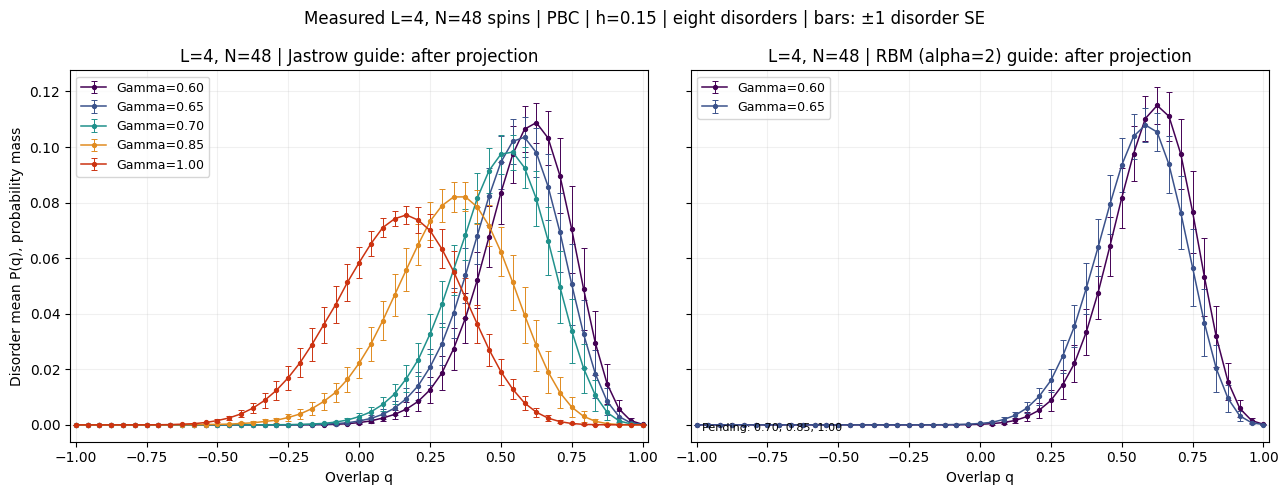

In [19]:
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
for ax,kind in zip(axes,['jastrow','rbm_2']):
    for (g,k),(q,values,mean,se) in sorted(broader_curves.items()):
        if k!=kind:continue
        ax.errorbar(q,mean,yerr=se,fmt='o-',ms=2.8,lw=1.1,elinewidth=.7,capsize=2,
                    capthick=.7,color=broader_colors[g],label=f'Gamma={g:.2f}')
    ax.set(title='L=4, N=48 | '+broader_names[kind]+' guide: after projection',xlabel='Overlap q',xlim=(-1.02,1.02))
    pending=[g for g in broader_protocol['fields'] if (g,kind) not in broader_curves]
    if pending:
        ax.text(.02,.03,'Pending: '+', '.join(f'{g:.2f}' for g in pending),transform=ax.transAxes,fontsize=8)
    ax.grid(alpha=.18);ax.legend(fontsize=9)
axes[0].set_ylabel('Disorder mean P(q), probability mass')
fig.suptitle('Measured L=4, N=48 spins | PBC | h=0.15 | eight disorders | bars: ±1 disorder SE')
broader_finish(fig,'broader_distributions')


The following diagnostics use the same
histograms and raw descendant measurements. The width is that of the
disorder-averaged distribution. Its variance splits into the average
within-disorder variance and the variance of disorder means; this distinguishes
changes within samples from a spread of sample centers. Uniform magnetization
and negative-overlap mass are displayed alongside width because the fixed
longitudinal field breaks spin-inversion symmetry.

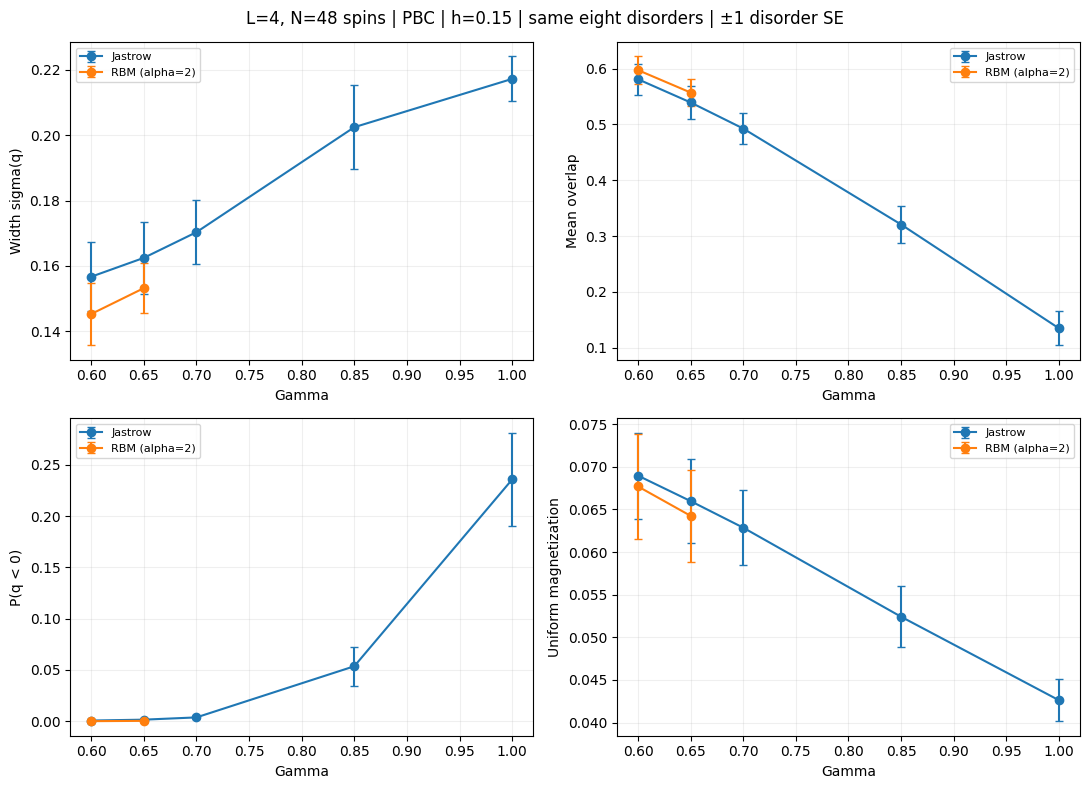

| Gamma | Guide | Width ± SE | Mean q | P(q<0) | Uniform m | Within variance | Between variance | Ancestry alarms / 16 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.60 | Jastrow | 0.1567 ± 0.0105 | 0.5809 | 0.00074 | 0.0690 | 0.01914 | 0.00542 | 6 |
| 0.60 | RBM (alpha=2) | 0.1453 ± 0.0096 | 0.5973 | 0.00014 | 0.0677 | 0.01690 | 0.00421 | 8 |
| 0.65 | Jastrow | 0.1625 ± 0.0110 | 0.5393 | 0.00160 | 0.0660 | 0.02040 | 0.00600 | 5 |
| 0.65 | RBM (alpha=2) | 0.1532 ± 0.0077 | 0.5571 | 0.00043 | 0.0642 | 0.01927 | 0.00421 | 14 |
| 0.70 | Jastrow | 0.1703 ± 0.0098 | 0.4926 | 0.00380 | 0.0629 | 0.02336 | 0.00566 | 5 |
| 0.85 | Jastrow | 0.2025 ± 0.0129 | 0.3206 | 0.05365 | 0.0524 | 0.03303 | 0.00796 | 6 |
| 1.00 | Jastrow | 0.2173 ± 0.0069 | 0.1346 | 0.23566 | 0.0426 | 0.04079 | 0.00641 | 5 |

Verified frozen input hashes, raw measurement hashes, replayed moments and spectra, and variance decomposition.


In [20]:
fig,axes=plt.subplots(2,2,figsize=(11,8))
for ax,key,error,label in zip(axes.flat,['width','mean_q','negative_mass','uniform_m'],
        ['width_se','mean_q_se','negative_mass_se','uniform_m_se'],
        ['Width sigma(q)','Mean overlap','P(q < 0)','Uniform magnetization']):
    for kind,color in [('jastrow','tab:blue'),('rbm_2','tab:orange')]:
        data=[r for r in broader_summary if r['kind']==kind]
        ax.errorbar([r['gamma'] for r in data],[r[key] for r in data],yerr=[r[error] for r in data],
                    fmt='o-',capsize=3,color=color,label=broader_names[kind])
    ax.set(xlabel='Gamma',ylabel=label);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('L=4, N=48 spins | PBC | h=0.15 | same eight disorders | ±1 disorder SE')
broader_finish(fig,'broader_distribution_diagnostics')
headers=['Gamma','Guide','Width ± SE','Mean q','P(q<0)','Uniform m','Within variance','Between variance','Ancestry alarms / 16']
table=[]
for r in broader_summary:
    table.append([f"{r['gamma']:.2f}",broader_names[r['kind']],f"{r['width']:.4f} ± {r['width_se']:.4f}",
                  f"{r['mean_q']:.4f}",f"{r['negative_mass']:.5f}",f"{r['uniform_m']:.4f}",
                  f"{r['within_disorder_variance']:.5f}",f"{r['between_disorder_variance']:.5f}",r['ancestry_alarms']])
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join(map(str,r))+' |' for r in table)))
(broader_figures/'l4_broader_summary.json').write_text(json.dumps(dict(created_utc=broader_protocol['created_utc'],
    measurement_snapshot_utc=broader_protocol.get('measurement_snapshot_utc'),
    complete_ensembles=broader_summary,production_coverage=broader_protocol['coverage'],
    measured_coverage=broader_protocol.get('measured_coverage'),ground_state_qualified=False),indent=2)+'\n')
print('Verified frozen input hashes, raw measurement hashes, replayed moments and spectra, and variance decomposition.')


In [21]:
# Paired field comparisons use the same eight disorders in the same order.
paired=[]
for kind in ['jastrow','rbm_2']:
    base=broader_curves[(.6,kind)][1]
    for (g,k),(q,values,mean,se) in sorted(broader_curves.items()):
        if k!=kind or g<=.6:continue
        change=broader_width(values)-broader_width(base)
        leave=np.array([broader_width(np.delete(values,i,axis=0))-broader_width(np.delete(base,i,axis=0)) for i in range(8)])
        error=float(np.sqrt(7/8*np.sum((leave-leave.mean())**2)))
        within=lambda a:a@(q*q)-(a@q)**2
        delta=within(values)-within(base)
        paired.append(dict(kind=kind,gamma=g,reference_gamma=.6,width_change=float(change),
            paired_width_change_se=error,width_ratio=float(broader_width(values)/broader_width(base)),
            within_variance_change=float(delta.mean()),within_variance_change_se=float(delta.std(ddof=1)/np.sqrt(8))))
headers=['Guide','Gamma','Width change from 0.60 ± paired SE','Width ratio','Within-disorder variance change ± SE']
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join([broader_names[r['kind']],f"{r['gamma']:.2f}",
        f"{r['width_change']:.4f} ± {r['paired_width_change_se']:.4f}",f"{r['width_ratio']:.3f}",
        f"{r['within_variance_change']:.5f} ± {r['within_variance_change_se']:.5f}"])+' |' for r in paired)))
saved=json.loads((broader_figures/'l4_broader_summary.json').read_text());saved['paired_field_comparisons']=paired
(broader_figures/'l4_broader_summary.json').write_text(json.dumps(saved,indent=2)+'\n')


| Guide | Gamma | Width change from 0.60 ± paired SE | Width ratio | Within-disorder variance change ± SE |
| --- | --- | --- | --- | --- |
| Jastrow | 0.65 | 0.0058 ± 0.0023 | 1.037 | 0.00126 ± 0.00036 |
| Jastrow | 0.70 | 0.0136 ± 0.0052 | 1.087 | 0.00422 ± 0.00114 |
| Jastrow | 0.85 | 0.0458 ± 0.0137 | 1.292 | 0.01389 ± 0.00210 |
| Jastrow | 1.00 | 0.0606 ± 0.0142 | 1.387 | 0.02166 ± 0.00308 |
| RBM (alpha=2) | 0.65 | 0.0079 ± 0.0044 | 1.055 | 0.00237 ± 0.00095 |

7965

The fine scan retains the full
$L=4$ grid $0.55,0.56,\ldots,0.70$. Original $L=6$ coverage remains
$0.60,0.65,0.70,0.85,1.00$, supplemented by the lower-field fine grid.
No incomplete ensemble is plotted here. Frozen production measurements, guide
models for new replays, source files, seeds, checkpoint ancestry and failures
remain with this snapshot or the source campaigns; replay checkpoints are retained.
No matched-size crossing or collapse is inferred from this report.

### Spatial-renormalization comparison with these higher-field distributions

**The current RG model reproduces the overall field trend, with a systematic shift toward lower overlap.**
The calculation uses the same five fields and eight disorder realizations, with
(m, chi)=(6,8): 48 physical spins → 16 triangles → four superblocks.
A direct sparse eigensolver solves the 8^4=4096-dimensional effective Hamiltonian.
Physical P(q) is measured using 16,384 independent conditional Born replica pairs
per disorder and field. DMRG and Markov-chain projection are not used in this calculation.

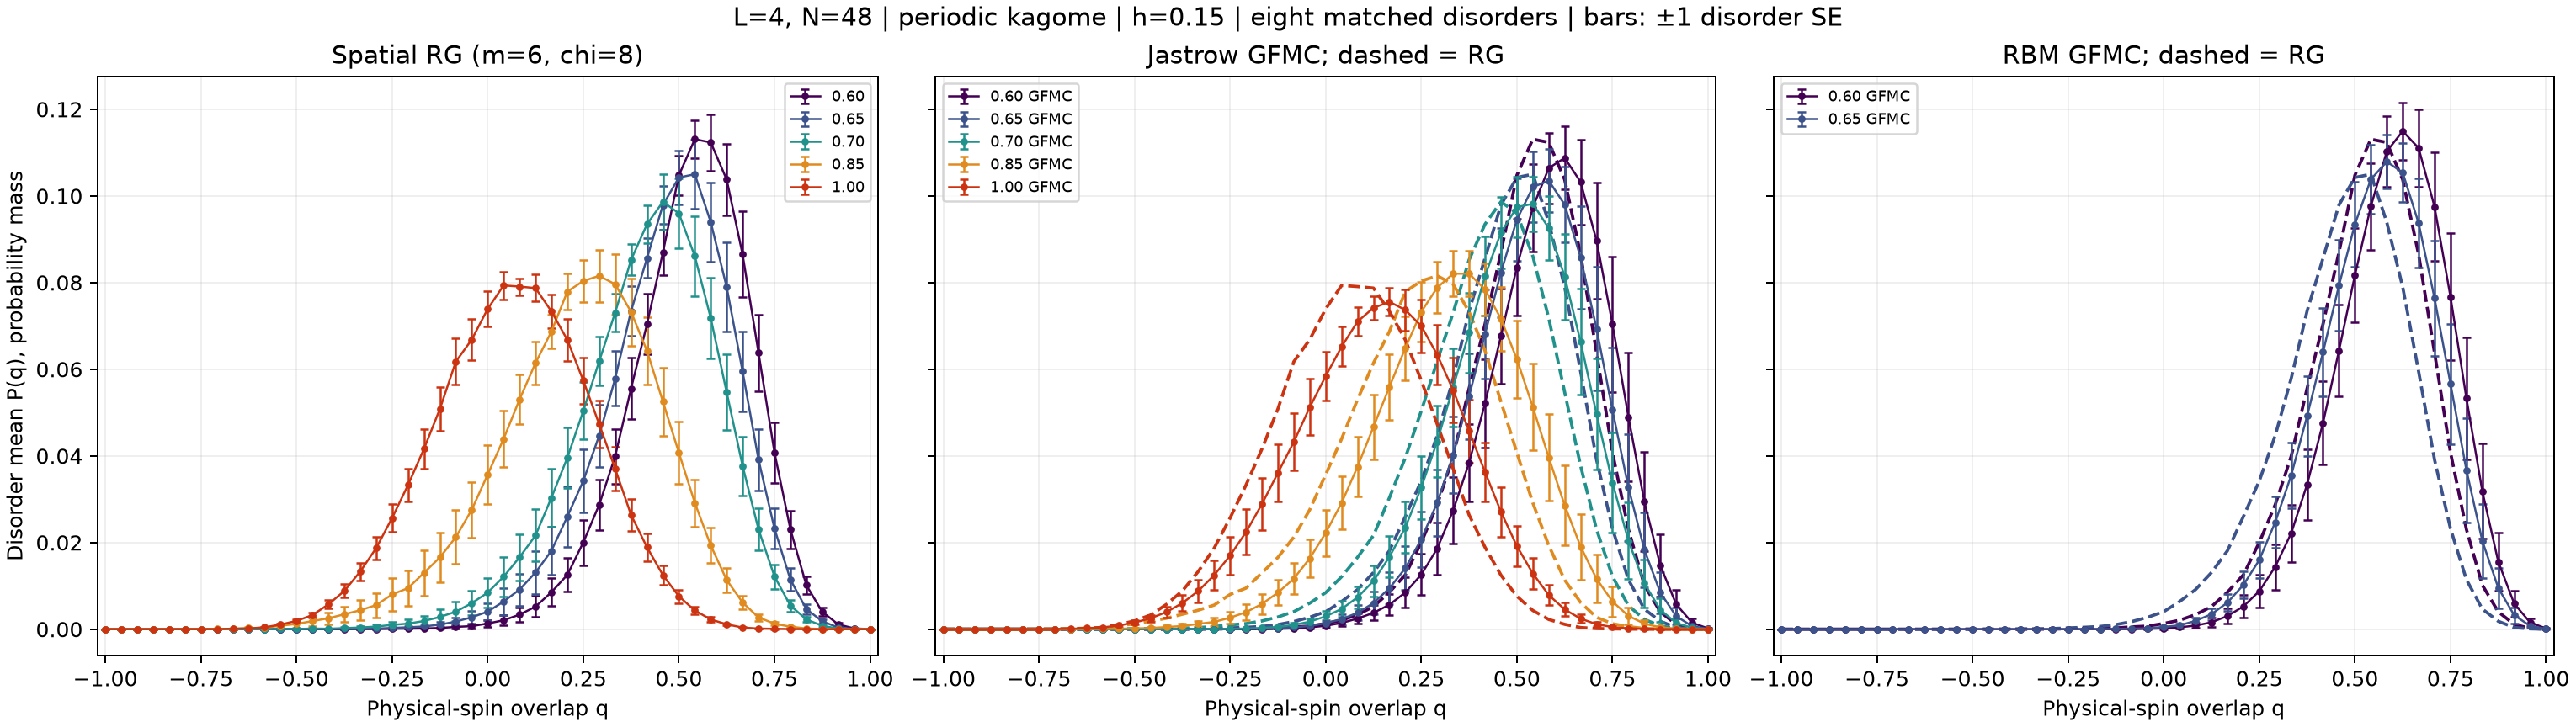

Dashed curves are RG; solid curves in the comparison panels are the frozen GFMC
histograms above. TV distances between the disorder means are .139, .157, .167,
.157 and .140 against Jastrow at Gamma=.60,.65,.70,.85,1.00, respectively.
The single-disorder checks with full triangle retention (m=8, chi=8) change
P(q) by TV=.018–.030; superblock retention and partition convergence remain untested.
All 45 planned cases completed, including the five retention checks.

[Detailed results and diagnostics](triangle_effective_higher_field_distributions.ipynb).
[Raw data and source provenance](../data/kagome/triangle_rg_higher_fields_v1/README.md).
The GFMC references remain preliminary; this comparison does not establish finite-size scaling.


## L=4, N=48: uniform polarization and nonuniform overlap

**The three lines in each panel** (brackets denote an equal average over disorders):

- **Black circles — mean overlap:** $[Q_J]_J=[N^{-1}\sum_i m_{i,J}^2]_J$.
- **Orange squares — uniform contribution:** $[U_J]_J=[\bar m_J^2]_J$, from the spatially averaged magnetization.
- **Blue triangles — nonuniform contribution:** $[V_J]_J=[N^{-1}\sum_i(m_{i,J}-\bar m_J)^2]_J$, from spatial variation of local magnetizations.

At each field, **black = orange + blue**. Error bars are $\pm1$ standard error across eight disorders.

For fixed disorder $J$, two independent configurations $s,t$ have overlap
$$q(s,t)=\frac1N\sum_i s_i t_i,\qquad
m_{i,J}=\langle Z_i\rangle_J,\qquad \bar m_J=\frac1N\sum_i m_{i,J}.$$
Independence gives $\langle s_i t_i\rangle_J=m_{i,J}^2$. Since
$\sum_i(m_{i,J}-\bar m_J)=0$, the mean overlap decomposes exactly as
$$Q_J\equiv\langle q\rangle_J=\frac1N\sum_i m_{i,J}^2
=\underbrace{\bar m_J^2}_{U_J:\ \text{uniform}}
+\underbrace{\frac1N\sum_i(m_{i,J}-\bar m_J)^2}_{V_J:\ \text{nonuniform}}.$$
The first term measures the contribution of **uniform polarization** to the
mean overlap. The second measures a **reproducible nonuniform local pattern**.
We evaluate both terms within each disorder, then average the eight disorders
equally: $[\bar m_J^2]_J$ is not $[\bar m_J]_J^2$.
This decomposes the **mean overlap**, not the histogram width or peak height.

The hypothesis is that the sharp, high-overlap low-$\Gamma$ peaks reflect
stronger freezing. A dominant nonuniform contribution would support the local
pattern part of that interpretation and show that uniform polarization explains
only a small fraction of the overlap. The inequality $h<\Gamma$ alone does not
exclude ferromagnetic order. Nonuniform polarization can also arise from a
field-pinned response to quenched disorder or other spatial order; it is not
by itself a glass order parameter in a field.

**Estimator from saved GFMC measurements.** Within one run and disorder (indices
suppressed), let $s_{cwi}^{(a)}$ be the tagged spin and $n_{cw}^{(a)}$ its
descendant count in population $a$, cycle $c$, walker $w$. With $C$ cycles,
$W$ walkers and $\sum_w n_{cw}^{(a)}=W$, compute
$$\widehat m_i^{(a)}=\frac1C\sum_{c=1}^C\sum_{w=1}^W
\frac{n_{cw}^{(a)}}W s_{cwi}^{(a)},\qquad
\widehat{\bar m}^{(a)}=\frac1N\sum_i\widehat m_i^{(a)},\qquad
\delta\widehat m_i^{(a)}=\widehat m_i^{(a)}-\widehat{\bar m}^{(a)}.$$
Average all six pairs of the four separately branching populations:
$$\widehat Q=\frac16\sum_{a<b}\frac1N\sum_i\widehat m_i^{(a)}\widehat m_i^{(b)},
\qquad \widehat U=\frac16\sum_{a<b}\widehat{\bar m}^{(a)}\widehat{\bar m}^{(b)},
\qquad \widehat V=\frac16\sum_{a<b}\frac1N\sum_i
\delta\widehat m_i^{(a)}\delta\widehat m_i^{(b)}.$$
Cross-population products avoid the positive self-squaring noise term
$\mathbb E[\widehat m^2]=(\mathbb E[\widehat m])^2+\operatorname{Var}(\widehat m)$;
they do not remove shared projection or mixing bias. The code checks
$$\widehat Q=\widehat U+\widehat V=\sum_q q\,\widehat P_J(q)$$
and agreement with the saved production mean overlap to tolerance $10^{-12}$.
Finite-sample estimates are not clipped to zero. This is distinct from the
single-snapshot second moment $\langle(N^{-1}\sum_i Z_i)^2\rangle$.

**Disorder averages and errors.** For any $X\in\{Q,U,V\}$, average two repeats
within each disorder, then $D=8$ disorders equally:
$$\widehat X_J=\frac{\widehat X_{J,0}+\widehat X_{J,1}}2,\qquad
\overline X=\frac1D\sum_J\widehat X_J,\qquad
\operatorname{SE}(\overline X)=
\sqrt{\frac{\sum_J(\widehat X_J-\overline X)^2}{D(D-1)}}.$$
The plotted curves are $\overline Q,\overline U,\overline V$ with capped
$\pm1$ disorder-SE bars. The nonuniform fraction is the ratio of disorder means,
$f=\overline V/\overline Q$. For its delete-one-disorder jackknife, define
$$f_{(-J)}=\frac{\sum_{K\ne J}\widehat V_K}{\sum_{K\ne J}\widehat Q_K},\qquad
\bar f_{\mathrm{leave}}=\frac1D\sum_J f_{(-J)},\qquad
\operatorname{SE}_{\mathrm{jack}}(f)=
\sqrt{\frac{D-1}{D}\sum_J(f_{(-J)}-\bar f_{\mathrm{leave}})^2}.$$
These errors describe variation across disorder estimates; they do not bound
systematic sampling or projection bias. Every ancestry alarm is retained with
equal weight.


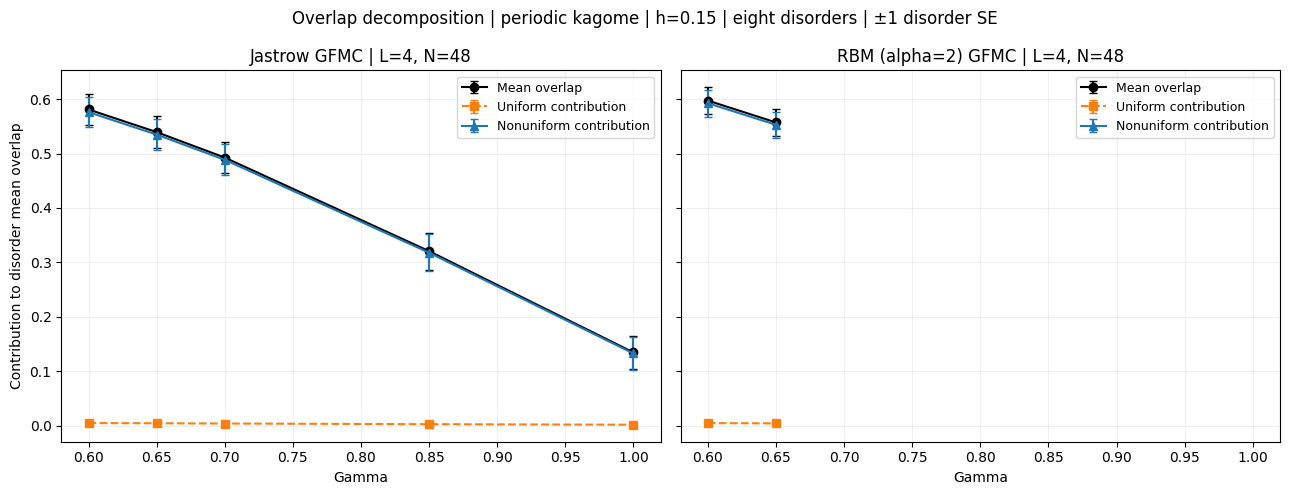

| Gamma | Guide | Mean q ± SE | Uniform contribution ± SE | Nonuniform contribution ± SE | Nonuniform fraction ± jackknife SE | Ancestry alarms / 16 |
| --- | --- | --- | --- | --- | --- | --- |
| 0.60 | Jastrow | 0.58095 ± 0.02782 | 0.00493 ± 0.00066 | 0.57602 ± 0.02768 | 0.992 ± 0.001 | 6 |
| 0.60 | RBM (alpha=2) | 0.59730 ± 0.02452 | 0.00484 ± 0.00079 | 0.59245 ± 0.02447 | 0.992 ± 0.001 | 8 |
| 0.65 | Jastrow | 0.53933 ± 0.02928 | 0.00452 ± 0.00063 | 0.53481 ± 0.02914 | 0.992 ± 0.001 | 5 |
| 0.65 | RBM (alpha=2) | 0.55709 ± 0.02451 | 0.00433 ± 0.00067 | 0.55276 ± 0.02432 | 0.992 ± 0.001 | 14 |
| 0.70 | Jastrow | 0.49255 ± 0.02842 | 0.00408 ± 0.00053 | 0.48847 ± 0.02832 | 0.992 ± 0.001 | 5 |
| 0.85 | Jastrow | 0.32064 ± 0.03373 | 0.00283 ± 0.00036 | 0.31781 ± 0.03361 | 0.991 ± 0.001 | 6 |
| 1.00 | Jastrow | 0.13456 ± 0.03026 | 0.00185 ± 0.00021 | 0.13271 ± 0.03011 | 0.986 ± 0.002 | 5 |

Checked decomposition against measured P(q) and production q for 112 runs.


At Gamma=0.60, **Jastrow**: the nonuniform contribution accounts for **99.2%** of the disorder mean overlap (±0.1 percentage points, disorder jackknife SE).

At Gamma=0.60, **RBM (alpha=2)**: the nonuniform contribution accounts for **99.2%** of the disorder mean overlap (±0.1 percentage points, disorder jackknife SE).

In [22]:
%matplotlib inline
from pathlib import Path
import hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/kagome').is_dir())
broader_folder=root/'data/kagome/ltfim_disorder_scaling_v1/broader_histograms/20261103T035100Z_preview'
broader_protocol=json.loads((broader_folder/'protocol.json').read_text())
for name,expected in broader_protocol['input_sha256'].items():
    assert hashlib.sha256((broader_folder/name).read_bytes()).hexdigest()==expected,name
broader_rows=json.loads((broader_folder/'projected_distributions.json').read_text())['rows']
broader_figures=root/'figures/simple_overlap';broader_figures.mkdir(parents=True,exist_ok=True)
broader_names={'jastrow':'Jastrow','rbm_2':'RBM (alpha=2)'}
def broader_finish(fig,name):
    fig.tight_layout()
    for suffix in ['png','pdf']:
        fig.savefig(broader_figures/(name+'.'+suffix),dpi=180,bbox_inches='tight')
    plt.show()

import importlib.util
polarization_source=root/'code/transformer_qmc/overlap_polarization.py'
spec=importlib.util.spec_from_file_location('overlap_polarization',polarization_source)
polarization_module=importlib.util.module_from_spec(spec);spec.loader.exec_module(polarization_module)
polarization_runs=[]
for r in broader_rows:
    t=r['task']
    assert t['L']==4 and t['audit']=='main' and r['replay_verified']
    raw_path=broader_folder/r['raw_file']
    assert hashlib.sha256(raw_path.read_bytes()).hexdigest()==r['raw_sha256']
    with np.load(raw_path) as raw:
        result=polarization_module.polarization_components(raw['tags'],raw['counts'])
    q=np.asarray(r['q_grid']);mass=np.asarray(r['mass'])
    np.testing.assert_allclose(result['mean_q'],q@mass,atol=1e-12,rtol=0)
    np.testing.assert_allclose(result['mean_q'],r['q'],atol=1e-12,rtol=0)
    polarization_runs.append(dict(task=t,raw_file=r['raw_file'],raw_sha256=r['raw_sha256'],
        provenance=r['provenance'],ancestry_alarm=r['ancestry_alarm'],**result))
polarization_disorders=[];polarization_summary=[]
component_keys=['mean_q','uniform_squared','nonuniform']
for gamma,kind in sorted({(r['task']['gamma'],r['task']['kind']) for r in polarization_runs}):
    group=[r for r in polarization_runs if (r['task']['gamma'],r['task']['kind'])==(gamma,kind)]
    assert len(group)==16
    values=[]
    for sid in range(60000,60008):
        repeats=[r for r in group if r['task']['sample_id']==sid]
        assert sorted(r['task']['repeat'] for r in repeats)==[0,1]
        value=np.mean([[r[key] for key in component_keys] for r in repeats],axis=0)
        values.append(value)
        polarization_disorders.append(dict(L=4,N=48,gamma=gamma,kind=kind,sample_id=sid,
            **dict(zip(component_keys,map(float,value))),
            ancestry_alarms=sum(r['ancestry_alarm'] for r in repeats)))
    values=np.asarray(values)
    np.testing.assert_allclose(values[:,0],values[:,1]+values[:,2],atol=1e-12,rtol=0)
    means=values.mean(axis=0);errors=values.std(axis=0,ddof=1)/np.sqrt(8)
    leave=np.asarray([np.delete(values,i,axis=0).mean(axis=0) for i in range(8)])
    assert means[0]>0 and (leave[:,0]>0).all(), 'Nonuniform fraction requires nonzero mean overlap'
    fractions=leave[:,2]/leave[:,0]
    fraction_se=float(np.sqrt(7/8*np.sum((fractions-fractions.mean())**2)))
    polarization_summary.append(dict(L=4,N=48,gamma=gamma,kind=kind,
        **dict(zip(component_keys,map(float,means))),
        **{key+'_se':float(error) for key,error in zip(component_keys,errors)},
        nonuniform_fraction=float(means[2]/means[0]),nonuniform_fraction_se=fraction_se,
        ancestry_alarms=sum(r['ancestry_alarm'] for r in group),disorders=8,runs=16))
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
styles=[('mean_q','Mean overlap','black','o-'),
        ('uniform_squared','Uniform contribution','tab:orange','s--'),
        ('nonuniform','Nonuniform contribution','tab:blue','^-')]
for ax,kind in zip(axes,['jastrow','rbm_2']):
    data=[r for r in polarization_summary if r['kind']==kind]
    for key,label,color,fmt in styles:
        ax.errorbar([r['gamma'] for r in data],[r[key] for r in data],
                    yerr=[r[key+'_se'] for r in data],fmt=fmt,color=color,capsize=3,label=label)
    ax.set(title=broader_names[kind]+' GFMC | L=4, N=48',xlabel='Gamma')
    ax.grid(alpha=.2);ax.legend(fontsize=9)
axes[0].set_ylabel('Contribution to disorder mean overlap')
fig.suptitle('Overlap decomposition | periodic kagome | h=0.15 | eight disorders | ±1 disorder SE')
broader_finish(fig,'l4_overlap_polarization')
headers=['Gamma','Guide','Mean q ± SE','Uniform contribution ± SE','Nonuniform contribution ± SE',
         'Nonuniform fraction ± jackknife SE','Ancestry alarms / 16']
table=[]
for r in polarization_summary:
    table.append([f"{r['gamma']:.2f}",broader_names[r['kind']],
        *[f"{r[key]:.5f} ± {r[key+'_se']:.5f}" for key in component_keys],
        f"{r['nonuniform_fraction']:.3f} ± {r['nonuniform_fraction_se']:.3f}",r['ancestry_alarms']])
display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
    '\n'.join('| '+' | '.join(map(str,r))+' |' for r in table)))
polarization_output=dict(h=.15,L=4,N=48,source_snapshot=str(broader_folder.relative_to(root)),
    measurement_snapshot_utc=broader_protocol.get('measurement_snapshot_utc'),
    source_sha256=hashlib.sha256(polarization_source.read_bytes()).hexdigest(),
    estimator='Cross-population products of equal-cycle descendant-weighted local magnetizations',
    uncertainty='Disorder SE; fraction uses delete-one-disorder jackknife; excludes mixing and projection bias',
    ground_state_qualified=False,runs=polarization_runs,disorders=polarization_disorders,summary=polarization_summary)
(broader_figures/'l4_overlap_polarization.json').write_text(json.dumps(polarization_output,indent=2)+'\n')
print(f'Checked decomposition against measured P(q) and production q for {len(polarization_runs)} runs.')
for kind in ['jastrow','rbm_2']:
    low=next(r for r in polarization_summary if r['kind']==kind and r['gamma']==.6)
    display(Markdown(f"At Gamma=0.60, **{names[kind]}**: the nonuniform contribution accounts for "
        f"**{100*low['nonuniform_fraction']:.1f}%** of the disorder mean overlap "
        f"(±{100*low['nonuniform_fraction_se']:.1f} percentage points, disorder jackknife SE)."))


A dominant nonuniform contribution supports interpreting high overlap as a
reproducible spatial pattern rather than predominantly uniform polarization.
It does not establish spontaneous ferromagnetism or its absence, nor distinguish
glassy freezing from other nonuniform responses. That distinction continues to
rely on independent-start convergence, connected correlations, and size scaling.
The populations branch separately from the same frozen guide; agreement between
them does not by itself demonstrate exploration of competing sectors.


## Strong-field repair controls: L=2 and L=6, periodic boundaries
<!-- rbm-strong-field-repair-controls -->

**Hamiltonian and scope:** $H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j
-0.15\sum_iZ_i-\Gamma\sum_iX_i$, periodic kagome, $N=3L^2$.
$K_{ij}\sim U(0.5,1.5)$ independently, stored as $J_{ij}=-K_{ij}$, using
`default_rng(SeedSequence([20261027,L,sample_id,1]))`. These controls use
the prespecified disorder **60000** and training seed **0**; they are not
a disorder average. The weak-field investigation remains at **$h=0.15$**.

**Two corrections:**
1. The $N=108$ RBM Adam learning rate is reduced from $0.01$ to $0.001$.
   A matched 200-update ablation keeps the model initialization, chains,
   temperature ladder, sweeps, and disorder identical. Norm clipping did not
   prevent instability at the old Adam step. No sampler equilibrium formula
   or guide-ratio clipping is changed. Failed frozen transport/start checks
   now block guide selection; a completed optimizer is not a converged fit.
2. GFMC now accumulates branching weights and weighted-time integrals in
   log space. A preserved failing uniform-start run reproduces all-weight
   underflow with the old code. The numerical repair does not restore the
   ancestral diversity lost by a poor guide.

The interacting strong-field check uses **$\Gamma=4$**, with exact
diagonalization at **$L=2,N=12$**, and matched RBM/Jastrow projection at
**$L=6,N=108$**. Separate analytic $K=0$ independent-spin tests at $N=108$
are numerical controls, not kagome-disorder measurements. At $\Gamma=4$
both $L=6$ benchmark guides use an explicit Adam rate $0.001$; the Jastrow
comparison does not change its production default. Two benchmark-launch
failures (worker thread reinitialization and a shared status-file collision)
are retained alongside the successfully recovered runs.

The projection checks compare guide/uniform starts, doubled walkers, and
doubled equilibration/forward time. Each has four independently branching
physical populations and two repeats; overlap uses cross-population products.
Capped bars show repeat SE for this one disorder, not disorder uncertainty.
All raw tags, descendant counts, energies, checkpoints, seeds, failures,
and numerical/ancestry diagnostics remain available in the source bundle.


Repair artifact hashes verified: 171


### Matched L=6, N=108 optimizer ablation

| Gamma | Adam rate | Mean frozen energy | Min round trips | Min exchange |
|---|---|---|---|---|
| 1.50 | 0.001 | -182.74363 | 713 | 0.595 |
| 1.50 | 0.01 | -152.20712 | 60 | 0.264 |
| 4.00 | 0.001 | -442.63201 | 2091 | 0.860 |
| 4.00 | 0.01 | -422.24392 | 1358 | 0.761 |

**Preserved failure replay:** `RuntimeError('walker weights left the positive reals')`. The corrected first block completes with weight ESS 3.65/512; this old guide remains unqualified.

### Frozen retraining diagnostics

L=2 frozen RBM: exact variational energy error **0.00787714**, fidelity **0.99946475**. These evaluate the trained guide before GFMC.

| L / N | Gamma | Guide | Energy range across starts | Min round trips | Sampling alarms |
|---|---|---|---|---|---|
| 6 / 108 | 4.00 | jastrow | -445.21552 to -445.21068 | 9222 | none detected |
| 2 / 12 | 4.00 | rbm_2 | -49.65972 to -49.64522 | 16567 | none detected |
| 6 / 108 | 1.00 | rbm_2 | -147.09160 to -147.00335 | 1365 | none detected |
| 6 / 108 | 4.00 | rbm_2 | -444.18460 to -444.14874 | 9331 | none detected |

### Gamma=4 projection sensitivity checks
| L / N | Guide | Audit | Energy ± repeat SE | Mean q ± repeat SE | Min descendant ESS | Max lineage | Alarms |
|---|---|---|---|---|---|---|---|
| 2 / 12 | rbm_2 | main | -49.65869 ± 0.00051 | 0.000402 ± 0.000133 | 96.4 | 0.031 | 0/2 |
| 2 / 12 | rbm_2 | population | -49.66098 ± 0.00300 | 0.000130 ± 0.000196 | 198.6 | 0.016 | 0/2 |
| 2 / 12 | rbm_2 | start | -49.65374 ± 0.00035 | 0.000473 ± 0.000038 | 89.0 | 0.031 | 0/2 |
| 2 / 12 | rbm_2 | time | -49.65868 ± 0.00067 | 0.000816 ± 0.000650 | 90.0 | 0.031 | 0/2 |
| 6 / 108 | jastrow | main | -445.21364 ± 0.00206 | 0.000489 ± 0.000079 | 105.0 | 0.023 | 0/2 |
| 6 / 108 | jastrow | population | -445.21456 ± 0.00089 | 0.000242 ± 0.000014 | 196.2 | 0.012 | 0/2 |
| 6 / 108 | jastrow | start | -445.21397 ± 0.00143 | 0.000282 ± 0.000070 | 95.3 | 0.023 | 0/2 |
| 6 / 108 | jastrow | time | -445.21239 ± 0.00053 | 0.000461 ± 0.000066 | 94.2 | 0.031 | 0/2 |
| 6 / 108 | rbm_2 | main | -445.25152 ± 0.02481 | 0.000166 ± 0.000369 | 34.6 | 0.078 | 0/2 |
| 6 / 108 | rbm_2 | population | -445.14696 ± 0.01921 | 0.000368 ± 0.000146 | 77.5 | 0.043 | 0/2 |
| 6 / 108 | rbm_2 | start | -445.17143 ± 0.02685 | 0.000313 ± 0.000075 | 35.6 | 0.094 | 0/2 |
| 6 / 108 | rbm_2 | time | -445.21084 ± 0.03114 | -0.000084 ± 0.000196 | 20.3 | 0.148 | 0/2 |

**Residual sensitivity:** the L=2 uniform-start energy differs from exact by +0.005674, versus repeat SE 0.000349. The L=6 RBM audit means span 0.104565 in total energy. Numerical completion and passing ancestry thresholds therefore do not establish fully converged accuracy.

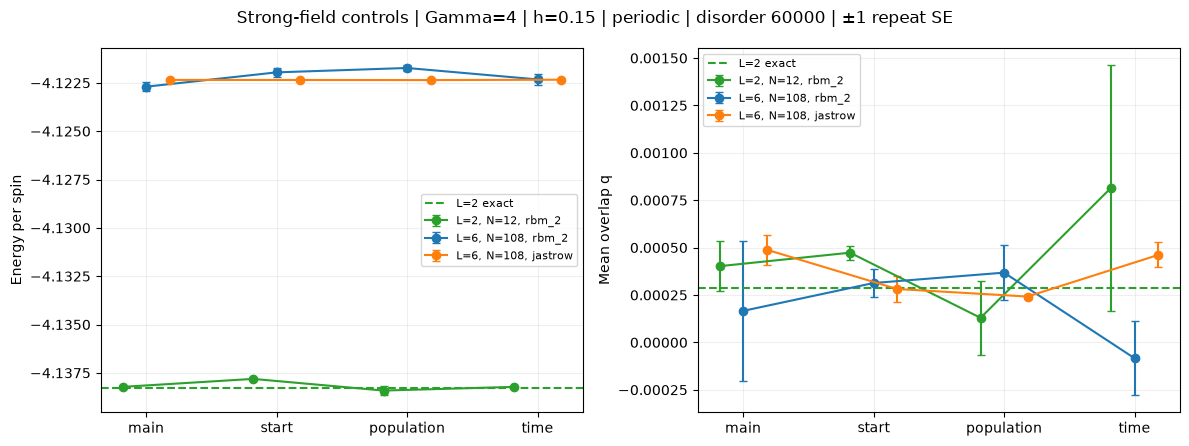

Ground-state qualification remains false: one-disorder controls do not validate the weak-field ensemble.


In [ ]:
repair_folder=root/'data/kagome/ltfim_disorder_scaling_v1/rbm_repair/20261103_v1'
repair_manifest=json.loads((repair_folder/'sha256.json').read_text())
for relative,digest in repair_manifest.items():
    assert hashlib.sha256((repair_folder/relative).read_bytes()).hexdigest()==digest,relative
print('Repair artifact hashes verified:',len(repair_manifest))
repair_optimizer=[]
for path in sorted((repair_folder/'optimizer').glob('g*.json')):
    r=json.loads(path.read_text())
    if 'diagnostics' not in r:continue
    repair_optimizer.append(r)
display(Markdown('### Matched L=6, N=108 optimizer ablation'))
table=['| Gamma | Adam rate | Mean frozen energy | Min round trips | Min exchange |',
       '|---|---|---|---|---|']
for r in repair_optimizer:
    ds=r['diagnostics']
    table.append(f"| {r['gamma']:.2f} | {r['lr']:.3g} | {np.mean([d['energy'] for d in ds]):.5f} | "
                 f"{min(d['round_trips'] for d in ds)} | {min(min(d['exchange_fraction']) for d in ds):.3f} |")
display(Markdown('\n'.join(table)))
repair_failure=json.loads((repair_folder/'failed_start_reproduction.json').read_text())
display(Markdown('**Preserved failure replay:** `'+repair_failure['original']['error']+'`. '
    'The corrected first block completes with weight ESS '
    f"{repair_failure['log_weight']['ess']:.2f}/512; this old guide remains unqualified."))
repair_fits=[]
for path in sorted((repair_folder/'validation').glob('**/training/*.json')):
    r=json.loads(path.read_text())
    if 'task' in r and 'diagnostics' in r:repair_fits.append(r)
display(Markdown('### Frozen retraining diagnostics'))
table=['| L / N | Gamma | Guide | Energy range across starts | Min round trips | Sampling alarms |',
       '|---|---|---|---|---|---|']
for r in repair_fits:
    t=r['task'];ds=r['diagnostics'];energies=[d['energy'] for d in ds]
    table.append(f"| {t['L']} / {3*t['L']**2} | {t['gamma']:.2f} | {t['kind']} | "
                 f"{min(energies):.5f} to {max(energies):.5f} | {min(d['round_trips'] for d in ds)} | "
                 f"{'; '.join(r.get('sampling_alarms',[])) or 'none detected'} |")
    if 'exact_evaluation' in r:
        ex=r['exact_evaluation']
        display(Markdown(f"L=2 frozen RBM: exact variational energy error **{ex['energy_error']:.6g}**, "
                         f"fidelity **{ex['fidelity']:.8f}**. These evaluate the trained guide before GFMC."))
display(Markdown('\n'.join(table)))
repair_projection=json.loads((repair_folder/'validation/projection_summary.json').read_text())['results']
repair_errors=[r for r in repair_projection if 'error' in r]
if repair_errors:display(Markdown('**Retained projection failures:** `'+str(repair_errors)+'`'))
repair_groups={}
for r in repair_projection:
    if 'error' in r:continue
    c=r['case'];repair_groups.setdefault((c['L'],c['kind'],c['audit']),[]).append(r)
table=['| L / N | Guide | Audit | Energy ± repeat SE | Mean q ± repeat SE | Min descendant ESS | Max lineage | Alarms |',
       '|---|---|---|---|---|---|---|---|']
for (L,kind,audit),rs in sorted(repair_groups.items()):
    assert sorted(r['case']['repeat'] for r in rs)==[0,1]
    def mean_se(key):
        x=np.array([r[key] for r in rs]);return x.mean(),x.std(ddof=1)/np.sqrt(len(x))
    e,ee=mean_se('energy');q,qe=mean_se('mean_q')
    table.append(f"| {L} / {3*L**2} | {kind} | {audit} | {e:.5f} ± {ee:.5f} | {q:.6f} ± {qe:.6f} | "
        f"{min(r['minimum_descendant_ess'] for r in rs):.1f} | {max(r['largest_lineage'] for r in rs):.3f} | {sum(r['ancestry_alarm'] for r in rs)}/2 |")
display(Markdown('### Gamma=4 projection sensitivity checks\n'+'\n'.join(table)))
exact_energy=next(r['exact']['energy'] for r in repair_projection if 'exact' in r)
l2_start=np.array([r['energy'] for r in repair_groups[(2,'rbm_2','start')]])
l6_rbm_means=[np.mean([r['energy'] for r in repair_groups[(6,'rbm_2',audit)]])
              for audit in ['main','start','population','time']]
display(Markdown('**Residual sensitivity:** the L=2 uniform-start energy differs from exact by '
    f"{l2_start.mean()-exact_energy:+.6f}, versus repeat SE {l2_start.std(ddof=1)/np.sqrt(2):.6f}. "
    f"The L=6 RBM audit means span {np.ptp(l6_rbm_means):.6f} in total energy. "
    'Numerical completion and passing ancestry thresholds therefore do not establish fully converged accuracy.'))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
audits=['main','start','population','time']
for L,kind,color,offset in [(2,'rbm_2','tab:green',-.18),(6,'rbm_2','tab:blue',0),(6,'jastrow','tab:orange',.18)]:
    for ax,key in zip(axes,['energy','mean_q']):
        means=[];errors=[]
        for audit in audits:
            values=np.array([r[key] for r in repair_groups.get((L,kind,audit),[])])
            assert len(values)==2
            if key=='energy':values=values/(3*L**2)
            means.append(values.mean());errors.append(values.std(ddof=1)/np.sqrt(2))
        ax.errorbar(np.arange(4)+offset,means,yerr=errors,fmt='o-',capsize=3,color=color,
                    label=f'L={L}, N={3*L**2}, {kind}')
truth=next(r['exact'] for r in repair_projection if 'exact' in r)
axes[0].axhline(truth['energy']/12,color='tab:green',ls='--',label='L=2 exact')
axes[1].axhline(truth['q_mean'],color='tab:green',ls='--',label='L=2 exact')
for ax in axes:
    ax.set_xticks(range(4),audits);ax.grid(alpha=.2);ax.legend(fontsize=8)
axes[0].set_ylabel('Energy per spin');axes[1].set_ylabel('Mean overlap q')
fig.suptitle('Strong-field controls | Gamma=4 | h=0.15 | periodic | disorder 60000 | ±1 repeat SE')
finish(fig,'strong_field_repair_controls')
print('Ground-state qualification remains false: one-disorder controls do not validate the weak-field ensemble.')


**Interpretation:** comparison with exact $L=2$ results is a direct accuracy
check. The uniform-start audit retains a discrepancy larger than its two-repeat
SE. At $L=6$, comparisons across guides, starts and projection settings provide
finite-budget consistency checks without an exact interacting reference; the
remaining audit spread must be resolved before claiming precision convergence.
Temperature round trips alone do not prove valley equilibration. The original
$L=6$ near-unit-overlap curves are not retroactively corrected by these tests.
The $L=4$ weak-field fine grid and original higher-field $L=6$ coverage remain
part of the campaign; corrected weak-field fits and full disorder ensembles
require their own convergence checks.

A separately logged corrected $L=6$ training pilot prioritizes
$\Gamma=0.55$ then $0.60$ (disorder 60000, seeds 0 and 1, fixed $h=0.15$).
Its pending fits are not included as physical measurements here.


### Interpretation and pending size coverage

These $L=4$ histograms are measured finite-population, finite-forward-time
estimates, not a ground-state convergence certificate. Replay agreement checks
reproducibility, not equilibration or sector exploration. Larger width by itself
does not establish greater glassiness.

The preserved fine scan is $L=4$, $N=48$, $\Gamma=0.55,0.56,\ldots,0.70$.
The original $L=6$, $N=108$ coverage is $0.60,0.65,0.70,0.85,1.00$, supplemented
by the lower-field fine grid. These frozen snapshots contain no complete
fine-grid or $L=6$ histogram ensemble. Pending curves are explicitly marked;
no incomplete disorder ensemble is plotted. Seeds, failures, invalid ratios,
ancestry alarms, raw measurements and checkpoints remain in the source bundles.
